# E120 · How many agents on the phones? Five models, one staffing decision, and the path between them

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: every call to the telephone centre of an Israeli bank in 1999, the **"Anonymous Bank" call-centre data** of the Technion SEE Center (Guedj and Mandelbaum 2000; free to use with acknowledgement), 440,849 calls with their waiting and service times |
| **You will learn** | Chaining models so that each one feeds the next: a **hierarchical count model** of arrivals with busy days and tilted days · a **mixture** for service times that sets aside a data artefact · a **censored survival model** of caller patience with a hazard in pieces · a **discrete-event queue simulator** driven by posterior draws, validated on days it has not seen · a **staffing decision** read off a frontier · and the habit this notebook is really about: writing down, at every step, what we chose, what we rejected, and what would change our mind, then showing how far the answer moves under each rejected choice |

## The question

A bank's operations manager has to post next month's roster: how many agents should be on the phones in
each hour of a working day? Too few and callers wait, lose patience and hang up. Too many and the bank
pays people to watch a silent switchboard.

The textbook answer is a formula. A. K. Erlang worked it out for the Copenhagen telephone exchange in
1917: if calls arrive as a Poisson process at a known rate, if each takes an exponentially distributed
time, and if callers wait for ever, the chance of having to wait follows from the arrival rate, the mean
call length and the number of agents. A century later most staffing software still starts there. Every
one of the three assumptions can be checked against data, and Brown, Gans, Mandelbaum, Sakov, Shen,
Zeltyn and Zhao (2005) did exactly that for a small Israeli bank whose call centre logged every call of
1999. Their paper is a classic of what they called queueing science, and the same data are free to use.

This notebook rebuilds the staffing answer from those calls, and it is written to show something that
finished analyses usually hide. A question like this is not answered by one model. It takes a chain of
them, each feeding the next: how many calls come in, how long each takes, how long a caller will wait,
how those three combine into a queue, and what roster is worth its cost. At every link there are several
defensible models, the first one we try is usually wrong, and one failure sends us back to the data for
a quantity we had not planned to measure at all. The path looks like this.

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from numba import njit
from scipy import special, stats

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub; nothing here uses JAX (see E89, E118)

RANDOM_SEED = 120
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
T_START = time.time()

INK, MUTED, LIGHT, GRID = "#222222", "#8a8a8a", "#d9d9d9", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SEQ = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def tidy(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.6)
    ax.set_axisbelow(True)

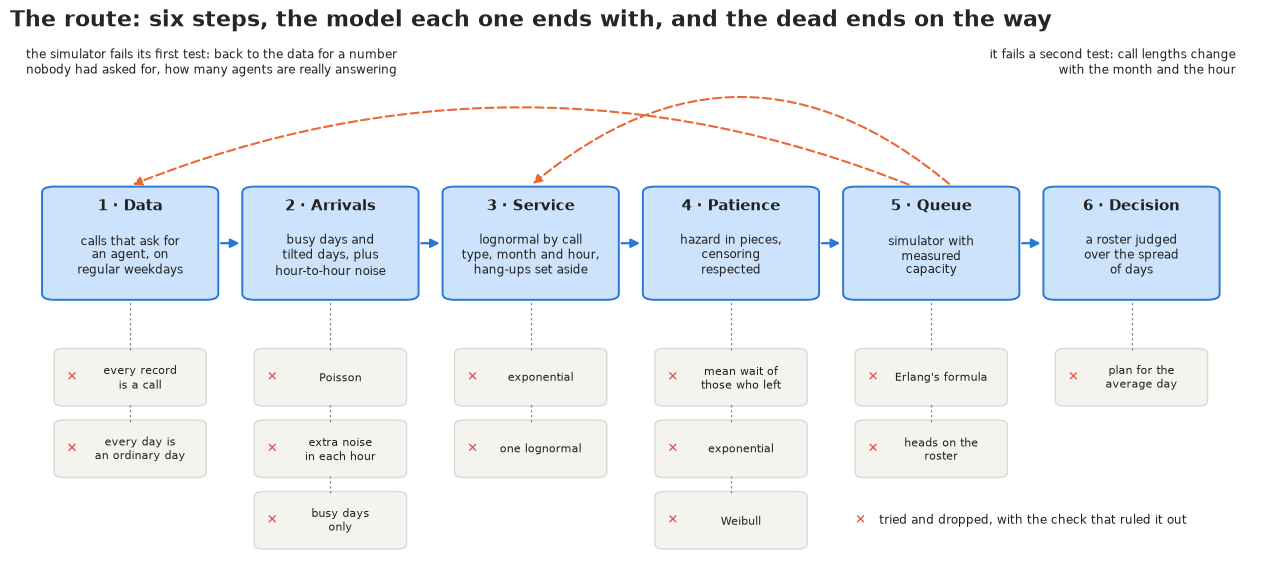

In [2]:
ROUTE = [  # step, what we end up using, what we try and drop on the way
    ("1 · Data", "calls that ask for\nan agent, on\nregular weekdays", ["every record\nis a call", "every day is\nan ordinary day"]),
    ("2 · Arrivals", "busy days and\ntilted days, plus\nhour-to-hour noise", ["Poisson", "extra noise\nin each hour", "busy days\nonly"]),
    ("3 · Service", "lognormal by call\ntype, month and hour,\nhang-ups set aside", ["exponential", "one lognormal"]),
    ("4 · Patience", "hazard in pieces,\ncensoring\nrespected", ["mean wait of\nthose who left", "exponential", "Weibull"]),
    ("5 · Queue", "simulator with\nmeasured\ncapacity", ["Erlang's formula", "heads on the\nroster"]),
    ("6 · Decision", "a roster judged\nover the spread\nof days", ["plan for the\naverage day"]),
]

fig, ax = plt.subplots(figsize=(12.5, 5.6))
for i, (step, kept, dropped) in enumerate(ROUTE):
    ax.add_patch(FancyBboxPatch((i - 0.42, 2.55), 0.84, 1.1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc="#cde2fb", ec=BLUE, lw=1.4))
    ax.text(i, 3.47, step, ha="center", va="center", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(i, 2.98, kept, ha="center", va="center", fontsize=8.6, color=INK, linespacing=1.25)
    if i < len(ROUTE) - 1:
        ax.add_patch(FancyArrowPatch((i + 0.44, 3.1), (i + 0.56, 3.1), arrowstyle="-|>", mutation_scale=13,
                                     color=BLUE, lw=1.6))
    for k, text in enumerate(dropped):
        y = 1.75 - 0.72 * k
        ax.plot([i, i], [y + 0.27, y + 0.45 if k else 2.53], color=MUTED, lw=0.9, ls=(0, (2, 2)))
        ax.add_patch(FancyBboxPatch((i - 0.36, y - 0.27), 0.72, 0.54, boxstyle="round,pad=0.02,rounding_size=0.05",
                                    fc="#f4f3ee", ec=LIGHT, lw=1.0))
        ax.text(i - 0.29, y, "✕", ha="center", va="center", fontsize=9, color=RED, fontweight="bold")
        ax.text(i + 0.05, y, text, ha="center", va="center", fontsize=8.2, color=INK, linespacing=1.2)
ax.add_patch(FancyArrowPatch((3.9, 3.68), (0, 3.68), connectionstyle="arc3,rad=0.2", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.add_patch(FancyArrowPatch((4.1, 3.68), (2, 3.68), connectionstyle="arc3,rad=0.42", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.text(-0.52, 4.92, "the simulator fails its first test: back to the data for a number\nnobody had asked for, "
        "how many agents are really answering", ha="left", va="center", fontsize=8.6, color=INK)
ax.text(5.52, 4.92, "it fails a second test: call lengths change\nwith the month and the hour", ha="right", va="center",
        fontsize=8.6, color=INK)
ax.text(3.62, 0.31, "✕", fontsize=9, color=RED, fontweight="bold", va="center")
ax.text(3.74, 0.31, "tried and dropped, with the check that ruled it out", fontsize=8.6, color=INK, va="center")
ax.set_xlim(-0.6, 5.6)
ax.set_ylim(-0.1, 5.2)
ax.axis("off")
ax.set_title("The route: six steps, the model each one ends with, and the dead ends on the way", loc="left");

Blue boxes are the steps and the model each one ends up with. Grey boxes are what we try first and drop,
each ruled out by a check we will show. The orange arrow is the one moment where the analysis runs
backwards.

Each step closes with a short box, **The choice**, that records what we kept, what we rejected and why,
and what evidence would make us choose differently. The last part reruns the decision under the rejected
choices, so that we can see which of them would have changed the roster and which were only worth an
afternoon.

| part | question | tool |
|---|---|---|
| 1 | What is a call, and what is an ordinary day? | cleaning choices, a calendar, a weekly heat map |
| 2 | How many calls arrive, and how sure can we be about tomorrow? | Poisson and negative binomial regressions, day effects, four predictive checks |
| 3 | How long does a call take? | exponential, lognormal, a mixture that isolates a data artefact |
| 4 | How long will a caller wait before hanging up? | survival analysis with censoring, a piecewise hazard |
| 5 | Do the three models, put together, behave like the real call centre? | a discrete-event simulator, replayed on real days, a calibration and a test |
| 6 | How many agents, hour by hour? | posterior predictive days, a cost-against-loss frontier, Erlang's formulas as rivals |
| 7 | Which of our choices mattered? | the decision redone under every rejected choice |

## 1 · What is a call, and what is an ordinary day?

In [3]:
data.describe("e120_calls")
calls = data.load("e120_calls")
calls["date"] = pd.to_datetime(calls["date"])
print(f"\n{len(calls):,} calls on {calls['date'].nunique()} days;", calls["outcome"].value_counts().to_dict())
calls.head(4)

e120_calls: One row per call in order of arrival (440,849 rows; the 3,599 PHANTOM records are dropped, customer ids are dropped and agents' names are replaced by codes): date, vru_entry_s (second of the day the call entered the voice response unit), vru_time (s), q_start_s (second of the day it joined the agents' queue; empty if it never queued), q_time (s in the queue), outcome (AGENT served, HANG hung up), ser_start_s (second of the day service began; empty if not served), ser_time (s of service), type (PS regular, PE English, IN internet, NE stock exchange, NW prospective customer, TT returned call), priority (2 = priority customer, moved up the queue by 90 s), identified (gave a customer id), agent (A01-A52; empty if none).
  source: 'Anonymous Bank' call-centre data, Technion SEE Center: every call to an Israeli bank's telephone centre in 1999, documented by Guedj and Mandelbaum (2000) and analysed in Brown et al. (2005, JASA 100:36-50). Terms: 'The data is free for use. If used, 


440,849 calls on 363 days; {'AGENT': 353143, 'HANG': 87706}


,date,vru_entry_s,vru_time,q_start_s,q_time,outcome,ser_start_s,ser_time,type,priority,identified,agent
0,1999-01-01,2,6,8.0,140,HANG,NaN,0,PS,2,1,NaN
1,1999-01-01,31,5,36.0,153,HANG,NaN,0,PS,2,1,NaN
2,1999-01-01,2052,11,NaN,0,HANG,NaN,0,PS,0,0,NaN
3,1999-01-01,2219,0,NaN,0,HANG,NaN,0,PS,0,0,NaN


Each row is one call. It enters a voice response unit (VRU), where the caller identifies and can do
simple banking without a person. A caller who wants an agent then either gets one at once or joins the
queue, and the record ends with `AGENT` (served) or `HANG` (the caller gave up). The table was derived
from the twelve monthly files by `tools/build_e120_calls.py`, which drops the customer identifiers,
replaces the agents' names with codes and removes the 3,599 records the documentation calls phantom.

Three decisions come before any model, and each one changes the numbers that follow.

**Which records are a demand for an agent?** A call that ends in the VRU never needed one. We keep the
calls that were served or that joined the queue.

**When did the demand begin?** The moment the call joined the queue, or, if it never queued, the moment
service began. The time of entering the VRU is earlier by about ten seconds and belongs to the machine.

**Which days are ordinary?** The Israeli working week runs from Sunday to Thursday, and the centre is
staffed from 7:00 to midnight on those days. On Friday it closes at 14:00 and it reopens on Saturday
evening. Within the working week some days are holidays, and a roster for an ordinary day should not be
learned from Passover.

In [4]:
calls["wants_agent"] = calls["outcome"].eq("AGENT") | calls["q_start_s"].notna()
a = calls[calls["wants_agent"]].copy()
a["t"] = (a["q_start_s"].fillna(a["ser_start_s"])
          .fillna(a["vru_entry_s"] + a["vru_time"].clip(0, 600)) % 86400).astype(float)
a["hour"] = (a["t"] // 3600).astype(int)
a["month"] = a["date"].dt.month
a["wd"] = a["date"].dt.day_name().str[:3]
a["lost"] = a["outcome"].eq("HANG")
print(f"calls that never asked for an agent: {1 - calls['wants_agent'].mean():.1%}; "
      f"calls that did: {len(a):,}, of which {a['lost'].mean():.1%} hung up before being served")

WD = ["Sun", "Mon", "Tue", "Wed", "Thu"]
work = a[a["wd"].isin(WD) & a["hour"].between(7, 23)]
per_day = work.groupby("date").size()
quiet = per_day[per_day < 900]
regular_days = per_day[per_day >= 900].index
reg = work[work["date"].isin(regular_days)].sort_values(["date", "t"]).reset_index(drop=True)
print(f"Sunday-Thursday days: {len(per_day)}; set aside as holidays or half days (fewer than 900 calls): "
      f"{len(quiet)}; regular weekdays: {len(regular_days)} with {len(reg):,} calls")
print("set aside:", ", ".join(f"{d:%d %b} ({n})" for d, n in quiet.items()))

calls that never asked for an agent: 5.4%; calls that did: 417,149, of which 15.3% hung up before being served
Sunday-Thursday days: 258; set aside as holidays or half days (fewer than 900 calls): 14; regular weekdays: 244 with 378,650 calls
set aside: 02 Mar (825), 08 Mar (471), 31 Mar (471), 01 Apr (110), 06 Apr (2), 07 Apr (148), 20 Apr (521), 21 Apr (250), 17 May (883), 20 May (465), 22 Jul (864), 12 Sep (151), 19 Sep (297), 20 Sep (131)


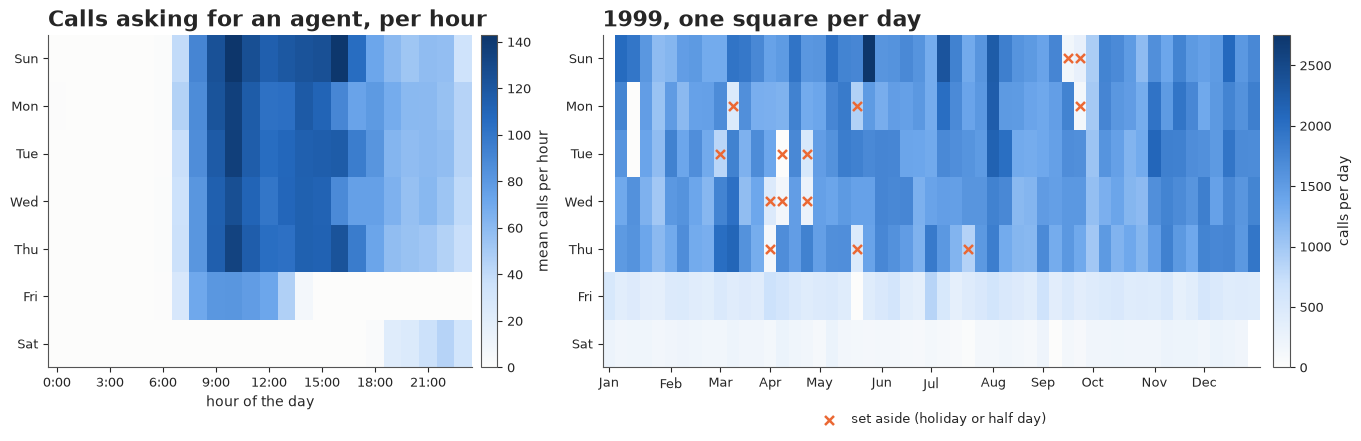

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1, 1.55]})
week = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
n_days = a.groupby("wd")["date"].nunique()
heat = (a.groupby(["wd", "hour"]).size().unstack(fill_value=0).reindex(week).div(n_days.reindex(week), axis=0)
        .reindex(columns=range(24), fill_value=0))
ax = axes[0]
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap=SEQ, vmin=0)
ax.set_yticks(range(7), week)
ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
ax.set_xlabel("hour of the day")
ax.grid(False)
ax.set_title("Calls asking for an agent, per hour", loc="left")
fig.colorbar(im, ax=ax, pad=0.02, label="mean calls per hour")

ax = axes[1]
daily = a.groupby("date").size().reindex(pd.date_range("1999-01-01", "1999-12-31"), fill_value=0)
col = (daily.index.dayofyear - 1 + 5) // 7           # 1 January 1999 was a Friday; weeks start on Sunday
row = (daily.index.dayofweek + 1) % 7
grid = np.full((7, col.max() + 1), np.nan)
grid[row, col] = daily.to_numpy()
im = ax.imshow(grid, aspect="auto", cmap=SEQ, vmin=0)
qd = daily.index.isin(quiet.index)
ax.scatter(col[qd], row[qd], marker="x", s=42, color=ORANGE, lw=1.8, label="set aside (holiday or half day)")
starts = pd.date_range("1999-01-01", "1999-12-01", freq="MS")
ax.set_xticks((starts.dayofyear - 1 + 5) // 7, [d.strftime("%b") for d in starts])
ax.set_yticks(range(7), week)
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=9)
ax.set_title("1999, one square per day", loc="left")
fig.colorbar(im, ax=ax, pad=0.02, label="calls per day");

The left panel is the week the roster has to cover: a steep climb from 7:00, a morning peak between
10:00 and 11:00, a long afternoon shoulder, and a quiet evening that still brings about 40% of the
peak's calls. The right panel is the year. The working days are far from uniform: there are pale columns in
early April (Passover) and in September (the autumn holidays), and the weeks themselves differ in
shade. The crosses are the days we set aside, the ones with fewer than 900 calls. That threshold was
chosen by looking at this picture, and it is the kind of choice that belongs in the open: a quiet
ordinary day and a busy half holiday are not separated by any rule the data carry.

> **The choice.** A call is a demand for an agent if it was served or queued; an ordinary day is a
> Sunday to Thursday with at least 900 such calls. *Rejected:* counting every record (the calls that
> finish in the VRU would inflate arrivals by about a twentieth), and keeping the holidays (they would
> be read as enormous day-to-day uncertainty in part 2). *What would change our mind:* a list of the
> bank's actual holidays and half days, which would replace the threshold with a fact.

## 2 · Arrivals: how many calls, and how sure can we be about tomorrow?

Staffing starts from the number of calls in each hour. We count them in a table of 244 days by 17
hours and ask for a model that can say what a day that has not happened yet will look like. That last
phrase matters. A model can describe the average day well and still be useless for a roster, because
the roster is posted in advance and must survive whatever day arrives.

We climb a ladder of four models. For each one we draw whole replicated years from the fitted model
and compare four summaries with the same summaries of the real year:

- the spread of the **daily totals** around their weekday average (do busy days exist?);
- the **hour-to-hour noise**, as the mean squared surprise, where the surprise of an hour is its count
  minus the average for that weekday and hour, divided by the square root of that average (a Poisson
  count has a mean squared surprise near 1);
- the correlation between a day's **morning and afternoon** surprises, and between its **morning and
  evening** surprises (does a busy morning announce a busy rest of the day?).

The rungs are these. **Poisson**: the rate is a weekday level times an hourly profile,
$\log\lambda_{dh} = \alpha + \beta_{w(d)} + \gamma_h$, which is the assumption behind Erlang's formula.
**Extra noise per hour**: the same rate with a negative binomial count, so that every hour gets its own
independent overdispersion. **Busy days**: a month effect and a day effect $\delta_d \sim
\mathcal{N}(0, \sigma_{\text{day}})$ that multiply the whole day's rate, still with negative binomial
noise. **Busy days and tilted days**: one more effect per day, $\tau_d\,x_h$ with $x_h$ rising linearly
from morning to night, so that a day can lean towards its morning or towards its evening.

In [6]:
N = reg.groupby(["date", "hour"]).size().unstack(fill_value=0)
days, HOURS, Y = N.index, N.columns.to_numpy(), N.to_numpy()
wd_idx = pd.Index(WD).get_indexer(days.day_name().str[:3])
mo_idx = days.month.to_numpy() - 1
tilt_x = (HOURS - HOURS.mean()) / 5.0
coords = {"day": days.strftime("%Y-%m-%d").to_numpy(dtype=object), "hour": HOURS, "weekday": WD,
          "month": np.arange(1, 13)}
MORN, AFT, EVE = slice(1, 6), slice(7, 12), slice(12, 17)        # 8:00-13:00, 14:00-19:00, 19:00-24:00
CHECKS = ["sd of daily totals", "mean squared surprise", "corr(morning, afternoon)", "corr(morning, evening)"]


def surprises(y):
    mu = np.stack([y[wd_idx == k].mean(0) for k in range(5)])[wd_idx]
    return (y - mu) / np.sqrt(np.maximum(mu, 1.0))


def check_stats(y):
    tot = y.sum(1)
    resid = tot - np.array([tot[wd_idx == k].mean() for k in range(5)])[wd_idx]
    z = surprises(y)
    am, af, ev = z[:, MORN].mean(1), z[:, AFT].mean(1), z[:, EVE].mean(1)
    return np.array([resid.std(), (z**2).mean(), np.corrcoef(am, af)[0, 1], np.corrcoef(am, ev)[0, 1]])


def arrival_model(kind):
    with pm.Model(coords=coords) as m:
        alpha = pm.Normal("alpha", np.log(90.0), 1.0)
        hour_eff = pm.ZeroSumNormal("hour_eff", sigma=1.0, dims="hour")
        weekday_eff = pm.ZeroSumNormal("weekday_eff", sigma=0.3, dims="weekday")
        eta = alpha + hour_eff[None, :] + weekday_eff[wd_idx][:, None]
        if kind in ("busy days", "busy + tilted days"):
            s_month = pm.HalfNormal("s_month", 0.2)
            month_eff = pm.ZeroSumNormal("month_eff", sigma=s_month, dims="month")
            s_day = pm.HalfNormal("s_day", 0.3)
            day_eff = pm.Normal("day_eff", 0.0, s_day, dims="day")
            eta = eta + month_eff[mo_idx][:, None] + day_eff[:, None]
        if kind == "busy + tilted days":
            s_tilt = pm.HalfNormal("s_tilt", 0.3)
            tilt = pm.Normal("tilt", 0.0, s_tilt, dims="day")
            eta = eta + tilt[:, None] * tilt_x[None, :]
        mu = pm.math.exp(eta)
        if kind == "Poisson":
            pm.Poisson("y", mu=mu, observed=Y, dims=("day", "hour"))
        else:
            phi = pm.Gamma("phi", 2.0, 0.05)
            pm.NegativeBinomial("y", mu=mu, alpha=phi, observed=Y, dims=("day", "hour"))
    return m


LADDER = ["Poisson", "extra noise per hour", "busy days", "busy + tilted days"]
obs_stats = check_stats(Y)
rep_stats, rep_example, diag = {}, {}, []
for kind in LADDER:
    with arrival_model(kind):
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
        ppc = pm.sample_posterior_predictive(idata.isel(draw=slice(None, None, 8)), random_seed=RANDOM_SEED,
                                             progressbar=False)
    yrep = ppc.posterior_predictive["y"].stack(s=("chain", "draw")).transpose("s", "day", "hour").to_numpy()
    rep_stats[kind] = np.array([check_stats(y) for y in yrep])
    rep_example[kind] = yrep[0]
    rhat, ess = az.rhat(idata), az.ess(idata)
    diag.append({"model": kind, "divergences": int(idata.sample_stats["diverging"].sum()),
                 "max r_hat": max(float(rhat[v].max()) for v in rhat.data_vars),
                 "min ESS": int(min(float(ess[v].min()) for v in ess.data_vars))})
    del ppc, yrep
idata_arr = idata                                  # the last rung is the one we keep
print(pd.DataFrame(diag).round(3).to_string(index=False))

table = pd.DataFrame({"observed": obs_stats}, index=CHECKS)
for kind in LADDER:
    lo, mid, hi = np.quantile(rep_stats[kind], [0.05, 0.5, 0.95], axis=0)
    table[kind] = [f"{m_:.3g} ({l_:.3g} to {h_:.3g})" for l_, m_, h_ in zip(lo, mid, hi)]
table["observed"] = table["observed"].map(lambda v: f"{v:.3g}")
print("\nreplicated years, median (5% to 95%):")
print(table.T.to_string())

               model  divergences  max r_hat  min ESS
             Poisson            0      1.004     6527
extra noise per hour            0      1.005     7413
           busy days            0      1.007      855
  busy + tilted days            0      1.018      509

replicated years, median (5% to 95%):
                     sd of daily totals mean squared surprise     corr(morning, afternoon)      corr(morning, evening)
observed                            254                  7.12                        0.601                       0.335
Poisson                 39 (36 to 41.9)  0.978 (0.94 to 1.01)    -0.00295 (-0.11 to 0.108)   0.00791 (-0.102 to 0.102)
extra noise per hour   109 (101 to 117)    6.96 (6.6 to 7.35)  -0.000607 (-0.111 to 0.104)  -0.00539 (-0.11 to 0.0993)
busy days              268 (253 to 283)   7.07 (6.67 to 7.46)        0.728 (0.675 to 0.77)      0.709 (0.656 to 0.761)
busy + tilted days     259 (245 to 272)   6.84 (6.49 to 7.25)       0.617 (0.564 to 0.671)      

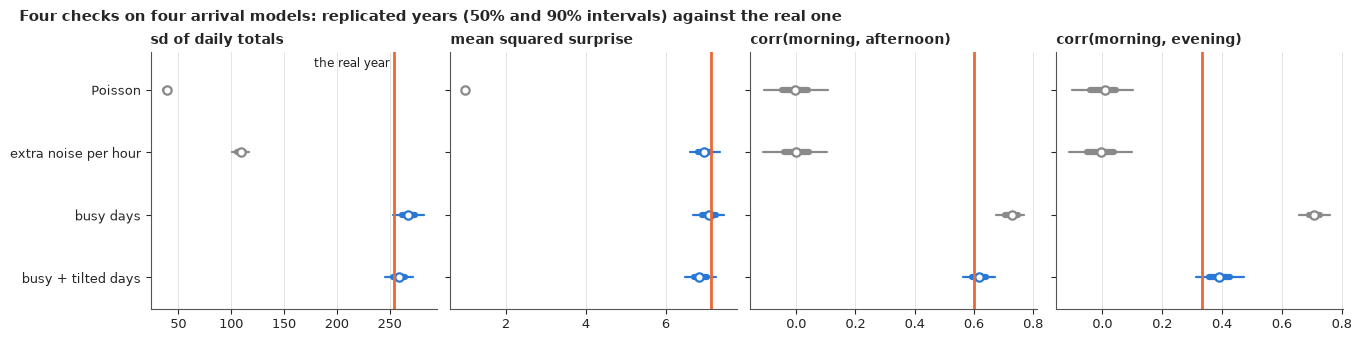

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.3), sharey=True)
for j, (ax, name) in enumerate(zip(axes, CHECKS)):
    for i, kind in enumerate(LADDER):
        lo, q25, mid, q75, hi = np.quantile(rep_stats[kind][:, j], [0.05, 0.25, 0.5, 0.75, 0.95])
        ok = lo <= obs_stats[j] <= hi
        ax.plot([lo, hi], [i, i], color=BLUE if ok else MUTED, lw=1.6, solid_capstyle="round")
        ax.plot([q25, q75], [i, i], color=BLUE if ok else MUTED, lw=4.5, solid_capstyle="round")
        ax.plot(mid, i, "o", ms=6, color="white", mec=BLUE if ok else MUTED, mew=1.6)
    ax.axvline(obs_stats[j], color=ORANGE, lw=2)
    ax.set_yticks(range(4), LADDER)
    ax.set_ylim(3.5, -0.6)
    ax.set_title(name, loc="left", fontsize=10)
    tidy(ax, grid="x")
axes[0].text(obs_stats[0], -0.42, "the real year ", color=INK, fontsize=8.5, ha="right", va="center")
fig.suptitle("Four checks on four arrival models: replicated years (50% and 90% intervals) against the real one",
             x=0.01, ha="left", fontsize=11);

All four fits are clean: no divergences, and the slowest parameter of the last model, its overall level,
has an r_hat of 1.02 and an effective sample of about 500. Read the figure one row at a time; an
interval turns blue when it contains the orange line.

**Poisson fails everywhere.** Its replicated years have daily totals that wander by about 40 calls
around the weekday average, where the real ones wander by about 250, and its hours are six or seven
times too quiet. A roster built on it would treat tomorrow's volume as known to within a few percent.

**Extra noise per hour fixes the wrong thing.** The negative binomial matches the hour-to-hour noise,
which is the statistic it was given a parameter for, and it would pass the check most people run. But
its daily totals still vary less than half as much as the real ones, and its mornings tell us nothing
about its afternoons, while in the real year the two are correlated at 0.6. Independent noise averages
out over a day. The real surprises do not: they arrive a day at a time.

**Busy days overshoot.** A single multiplier per day reproduces the spread of the daily totals, but now
the day moves too much in step: the model's mornings predict its evenings with a correlation near
0.7, and the real figure is about half that.

**Busy and tilted days pass all four.** Letting each day lean towards its morning or its evening brings
both correlations into line without spoiling the rest. The next figure shows what the two failed
middle rungs look like against the data, one dot per day.

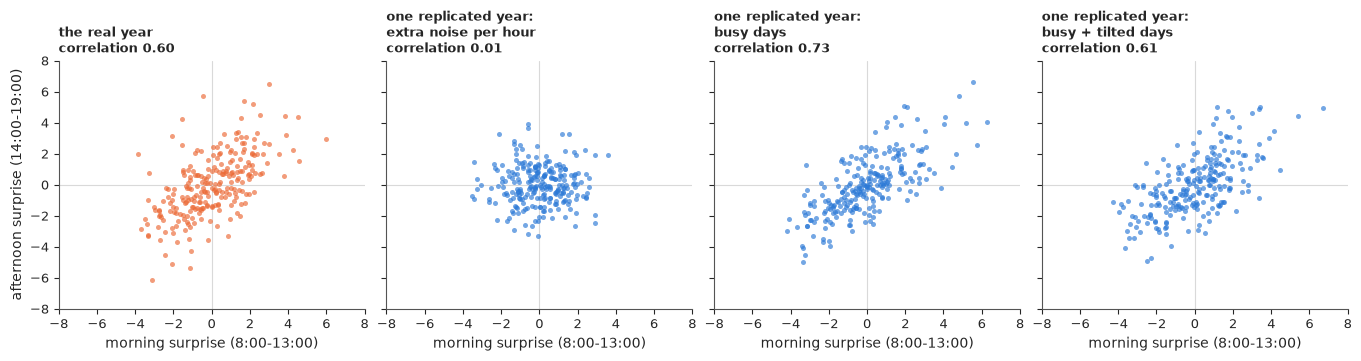

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.5), sharex=True, sharey=True)
panels = [("the real year", Y, ORANGE)] + [(f"one replicated year:\n{k}", rep_example[k], BLUE) for k in LADDER[1:]]
for ax, (title, y, colour) in zip(axes, panels):
    z = surprises(y)
    am, af = z[:, MORN].mean(1), z[:, AFT].mean(1)
    ax.scatter(am, af, s=13, color=colour, alpha=0.65, lw=0)
    ax.axhline(0, color=LIGHT, lw=0.8, zorder=0)
    ax.axvline(0, color=LIGHT, lw=0.8, zorder=0)
    ax.set_title(f"{title}\ncorrelation {np.corrcoef(am, af)[0, 1]:.2f}", loc="left", fontsize=9.5)
    ax.set_xlabel("morning surprise (8:00-13:00)")
    tidy(ax, grid=None)
axes[0].set_ylabel("afternoon surprise (14:00-19:00)")
axes[0].set_xlim(-8, 8)
axes[0].set_ylim(-8, 8);

In the real year a morning that runs ahead of its average is usually followed by an afternoon that
does too, loosely. Independent noise gives a round cloud. A single day effect gives a tight diagonal.
The last panel has the loose diagonal of the data.

           mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
alpha     4.423  0.010     4.408     4.439   689.194  1269.998  1.014      0.000    0.000
s_month   0.070  0.021     0.043     0.108  1020.373  1476.664  1.004      0.001    0.000
s_day     0.151  0.008     0.138     0.164  3632.017  2966.366  1.000      0.000    0.000
s_tilt    0.085  0.006     0.077     0.094  2461.992  2519.104  0.999      0.000    0.000
phi      30.026  0.987    28.474    31.632  5593.632  2824.221  1.001      0.013    0.017
expected calls on the target day: 1742 | peak hour: 10 with 158 calls | 90% interval for the day's total: [1294 2250]


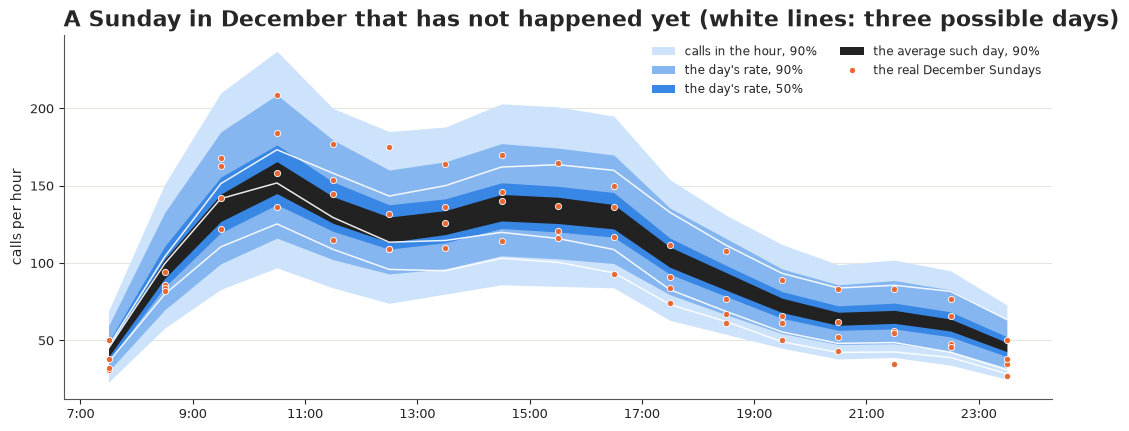

In [9]:
print(az.summary(idata_arr, var_names=["alpha", "s_month", "s_day", "s_tilt", "phi"], round_to=3).to_string())
pa = az.extract(idata_arr, num_samples=400, random_seed=RANDOM_SEED)
ARR = {v: pa[v].to_numpy() for v in ("alpha", "s_day", "s_tilt", "phi")}
ARR["hour_eff"] = pa["hour_eff"].transpose("sample", "hour").to_numpy()
ARR["weekday_eff"] = pa["weekday_eff"].transpose("sample", "weekday").to_numpy()
ARR["month_eff"] = pa["month_eff"].transpose("sample", "month").to_numpy()
N_POST = len(ARR["alpha"])
del idata_arr, idata, pa


def new_day_rates(j, weekday="Sun", month=12, surprise=True, gen=rng):
    """Hourly arrival rates of a day that has not happened yet, from posterior draw j."""
    eta = (ARR["alpha"][j] + ARR["hour_eff"][j] + ARR["weekday_eff"][j, WD.index(weekday)]
           + ARR["month_eff"][j, month - 1])
    if surprise:
        eta = eta + gen.normal(0, ARR["s_day"][j]) + gen.normal(0, ARR["s_tilt"][j]) * tilt_x
    return np.exp(eta)


def new_day_counts(lam, j, gen=rng):
    return gen.poisson(lam * gen.gamma(ARR["phi"][j], 1 / ARR["phi"][j], size=lam.shape))


gen = np.random.default_rng(RANDOM_SEED + 1)
draws = gen.integers(0, N_POST, 2000)
lam_new = np.array([new_day_rates(j, gen=gen) for j in draws])
cnt_new = np.array([new_day_counts(lam, j, gen) for lam, j in zip(lam_new, draws)])
lam_flat = np.array([new_day_rates(j, surprise=False) for j in range(N_POST)])
LAM_MEAN = lam_new.mean(0)                           # expected calls per hour on the target day

fig, ax = plt.subplots(figsize=(10.5, 4.2))
x = HOURS + 0.5
ax.fill_between(x, *np.quantile(cnt_new, [0.05, 0.95], axis=0), color="#cde2fb", lw=0, label="calls in the hour, 90%")
ax.fill_between(x, *np.quantile(lam_new, [0.05, 0.95], axis=0), color="#86b6ef", lw=0, label="the day's rate, 90%")
ax.fill_between(x, *np.quantile(lam_new, [0.25, 0.75], axis=0), color="#3987e5", lw=0, label="the day's rate, 50%")
ax.fill_between(x, *np.quantile(lam_flat, [0.05, 0.95], axis=0), color=INK, lw=0, label="the average such day, 90%")
for k in range(3):
    ax.plot(x, lam_new[k], color="white", lw=1.1, alpha=0.9)
dec_sundays = [d for d in days if d.month == 12 and d.day_name() == "Sunday"]
for d in dec_sundays:
    ax.plot(x, N.loc[d].to_numpy(), "o", ms=4.5, color=ORANGE, mec="white", mew=0.6,
            label="the real December Sundays" if d == dec_sundays[0] else None)
ax.set_xticks(range(7, 25, 2), [f"{h}:00" for h in range(7, 25, 2)])
ax.set_ylabel("calls per hour")
ax.legend(frameon=False, fontsize=8.5, ncol=2, loc="upper right")
ax.set_title("A Sunday in December that has not happened yet (white lines: three possible days)", loc="left")
tidy(ax)
print("expected calls on the target day:", int(LAM_MEAN.sum()), "| peak hour:", int(HOURS[LAM_MEAN.argmax()]),
      f"with {LAM_MEAN.max():.0f} calls | 90% interval for the day's total:",
      np.quantile(cnt_new.sum(1), [0.05, 0.95]).astype(int))

This is the first hand-over in the chain. From here on the planning day is **a Sunday at December's
level**, the busiest weekday in the busiest month, and what the arrival model passes on is this fan
and not a single curve. The thin black band is our uncertainty about the average such Sunday: with a
year of data it is narrow. The blue bands are the Sunday that will actually turn up. The day effect has
a standard deviation of about 0.15 on the log scale, so a day in the upper tail brings a quarter more
calls than the average one, all day long, and the tilt adds a further 0.085 per five hours of clock.
The orange dots are the four real December Sundays, which the fit has seen; they sit inside the bands
as they should, and they also show how different two Sundays of the same month can be.

> **The choice.** Arrivals are negative binomial counts around a rate with a weekday level, an hourly
> profile, a month effect, a day effect and a day tilt. *Rejected:* Poisson (no busy days at all),
> independent overdispersion per hour (right noise, wrong structure: its surprises cancel within a
> day), a day effect alone (days too rigid). *Considered and left for another day:* a random walk over
> the days of the year in place of month effects, and a Gaussian process over the hour in place of
> seventeen free hourly levels; with 244 days in every hour the hourly profile is already sharp.
> *What would change our mind:* a second year. With one year, a month effect cannot be told apart
> from growth, and we plan for December's level as if it were known.

## 3 · Service: how long does a call take?

The second input is the length of a call. Erlang's formula assumes it is exponential, a distribution
whose standard deviation equals its mean and whose most likely value is zero. We look at the calls
served on the regular weekdays and compare three candidates on a logarithmic clock, because call
lengths run from a second to over an hour.

In [10]:
served = reg[(~reg["lost"]) & (reg["ser_time"] > 0)].copy()
sec = served["ser_time"].to_numpy(float)
print(f"served calls: {len(sec):,} | mean {sec.mean():.0f} s, median {np.median(sec):.0f} s, "
      f"sd/mean {sec.std() / sec.mean():.2f} | under 10 s: {(sec < 10).mean():.1%}")
log_mu, log_sd = np.log(sec).mean(), np.log(sec).std()
print(f"exponential with the same mean puts {1 - np.exp(-10 / sec.mean()):.1%} under 10 s; "
      f"one lognormal (log mean {log_mu:.2f}, log sd {log_sd:.2f}) puts {stats.norm.cdf((np.log(10) - log_mu) / log_sd):.1%}")

served["early"] = served["month"] <= 10
short_month = served.groupby("month")["ser_time"].apply(lambda s: (s < 10).mean())
print("share of served calls under 10 s by month:", short_month.round(3).to_dict())

served calls: 317,481 | mean 193 s, median 116 s, sd/mean 1.47 | under 10 s: 5.1%
exponential with the same mean puts 5.1% under 10 s; one lognormal (log mean 4.67, log sd 1.22) puts 2.6%
share of served calls under 10 s by month: {1: 0.047, 2: 0.065, 3: 0.073, 4: 0.062, 5: 0.074, 6: 0.067, 7: 0.067, 8: 0.052, 9: 0.058, 10: 0.043, 11: 0.011, 12: 0.012}


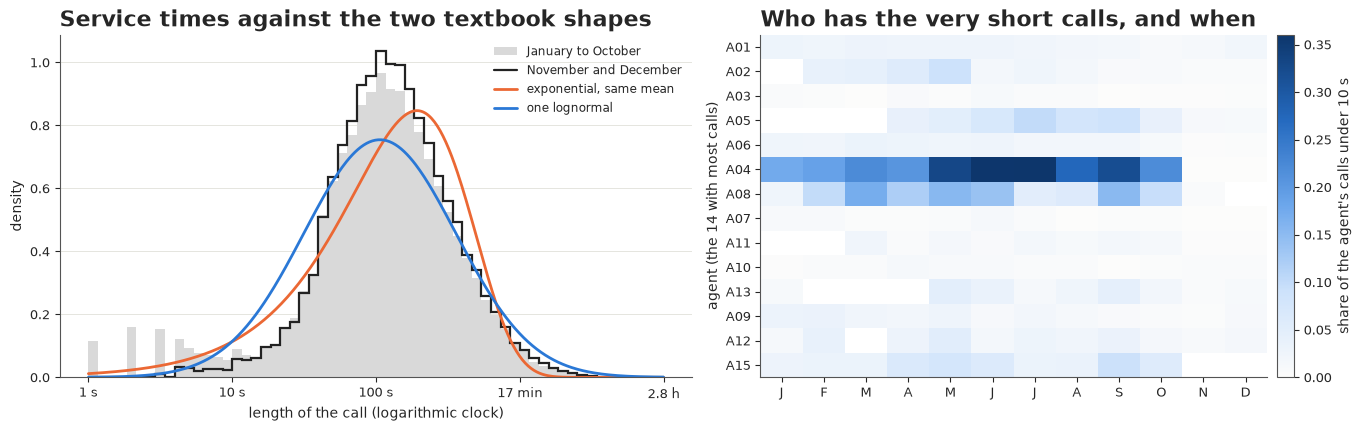

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
edges_log = np.linspace(0, 4, 61)
grid_s = np.logspace(0, 4, 400)
for flag, colour, label in ((True, LIGHT, "January to October"), (False, INK, "November and December")):
    h, _ = np.histogram(np.log10(served.loc[served["early"] == flag, "ser_time"]), bins=edges_log, density=True)
    ax.stairs(h, edges_log, color=colour, lw=1.6 if not flag else 0, fill=flag, label=label)
ax.plot(np.log10(grid_s), stats.expon(scale=sec.mean()).pdf(grid_s) * grid_s * np.log(10), color=ORANGE, lw=2,
        label="exponential, same mean")
ax.plot(np.log10(grid_s), stats.norm(log_mu, log_sd).pdf(np.log(grid_s)) * np.log(10), color=BLUE, lw=2,
        label="one lognormal")
ax.set_xticks(range(5), ["1 s", "10 s", "100 s", "17 min", "2.8 h"])
ax.set_xlabel("length of the call (logarithmic clock)")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Service times against the two textbook shapes", loc="left")
tidy(ax)

ax = axes[1]
top = served["agent"].value_counts().index[:14]
share = (served[served["agent"].isin(top)].assign(short=lambda d: d["ser_time"] < 10)
         .groupby(["agent", "month"])["short"].mean().unstack().reindex(top))
im = ax.imshow(share.to_numpy(), aspect="auto", cmap=SEQ, vmin=0)
ax.set_xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks(range(len(top)), top)
ax.set_ylabel("agent (the 14 with most calls)")
ax.grid(False)
fig.colorbar(im, ax=ax, pad=0.02, label="share of the agent's calls under 10 s")
ax.set_title("Who has the very short calls, and when", loc="left");

The grey histogram (January to October) has a main hump around two minutes and a scatter of calls
that last a few seconds. On this clock the exponential (orange) is too narrow and sits too far to the
right: it expects too few calls of about a minute and too many of five. It does get the share of
calls under ten seconds right, at about 5%, which is a coincidence worth remembering: a summary can
agree for the wrong reason. The single lognormal (blue) is centred on the main hump but is stretched
to the left by the very short calls, and ends up too wide on both sides.

The very short calls are the interesting part. Brown et al. (2005) report what the manager of the call
centre found: they "were primarily caused by agents who simply hung up on customers to obtain extra
rest time", and steps were taken to stop it in October 1999. The data say the same in two ways. The
black outline (November and December) has almost no calls under five seconds. And the right panel
shows that the very short calls belong to particular agents, one of whom closes between a fifth and a
third of all calls within ten seconds from January to October, and that they fade for everybody in
November.

So the short calls are real records of something that was not service. A model of how long a call
takes should not learn from them, and deleting everything under ten seconds would be too blunt: honest
calls can be short too. Brown et al. suggest a mixture model for the whole year, and that is what we
fit. Each call is either a hang-up, with a lognormal length of a few seconds, or a real call, with a
lognormal length that depends on the type of call (regular banking, stock exchange, internet support,
new customers and so on). The share of hang-ups is one number before November and another after it.

With 317,000 calls we do not need them one by one. Calls with the same length, type and period have
the same likelihood term, so we count them and weight the term, which leaves about 12,000 rows. The
model is wrapped in a function because we will need it again.

In [12]:
TYPES = ["PS", "NW", "NE", "IN", "TT", "PE"]
TYPE_NAME = {"PS": "regular", "NW": "new customer", "NE": "stock exchange", "IN": "internet", "TT": "returned call",
             "PE": "regular, English"}
sv = served[served["type"].isin(TYPES)]


def fit_service(drift):
    """Agents' hang-ups plus real calls, lognormal by call type; with drift, shifted by month and by hour."""
    keys = ["ser_time", "type", "month", "hour"] if drift else ["ser_time", "type", "early"]
    agg = sv.groupby(keys).size().rename("n").reset_index()
    x_s = agg["ser_time"].to_numpy(float)
    t_i = pd.Index(TYPES).get_indexer(agg["type"])
    p_i = ((agg["month"] > 10) if drift else ~agg["early"]).to_numpy().astype(int)
    w_n = agg["n"].to_numpy(float)
    with pm.Model(coords={"type": TYPES, "period": ["Jan-Oct", "Nov-Dec"], "month": np.arange(1, 13), "hour": HOURS}):
        mu = pm.Normal("mu", 5.0, 1.0, dims="type")
        sigma = pm.HalfNormal("sigma", 1.0, dims="type")
        loc = mu[t_i]
        if drift:
            s_month = pm.HalfNormal("s_month", 0.2)
            month_eff = pm.ZeroSumNormal("month_eff", sigma=s_month, dims="month")
            s_hour = pm.HalfNormal("s_hour", 0.2)
            hour_eff = pm.ZeroSumNormal("hour_eff", sigma=s_hour, dims="hour")
            loc = loc + month_eff[agg["month"].to_numpy() - 1] + hour_eff[agg["hour"].to_numpy() - 7]
        mu_short = pm.Normal("mu_short", np.log(4.0), 0.5)
        sigma_short = pm.HalfNormal("sigma_short", 0.5)
        w_short = pm.Beta("w_short", 1.0, 10.0, dims="period")
        lp_real = pm.logp(pm.LogNormal.dist(loc, sigma[t_i]), x_s)
        lp_short = pm.logp(pm.LogNormal.dist(mu_short, sigma_short), x_s)
        pm.Potential("weighted_loglik", (w_n * pt.logaddexp(pt.log(w_short[p_i]) + lp_short,
                                                            pt.log1p(-w_short[p_i]) + lp_real)).sum())
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    rhat = az.rhat(idata)
    print(f"{len(sv):,} calls in {len(agg):,} weighted rows; divergences: {int(idata.sample_stats['diverging'].sum())}; "
          f"max r_hat {max(float(rhat[v].max()) for v in rhat.data_vars):.3f}")
    show_vars = ["mu", "sigma", "mu_short", "sigma_short", "w_short"] + (["s_month", "s_hour"] if drift else [])
    print(az.summary(idata, var_names=show_vars, round_to=3)[["mean", "sd", "ess_bulk", "r_hat"]].to_string())
    ps = az.extract(idata, num_samples=N_POST, random_seed=RANDOM_SEED)
    n_s = ps.sizes["sample"]
    return {"mu": ps["mu"].transpose("sample", "type").to_numpy(),
            "sigma": ps["sigma"].transpose("sample", "type").to_numpy(),
            "month_eff": ps["month_eff"].transpose("sample", "month").to_numpy() if drift else np.zeros((n_s, 12)),
            "hour_eff": ps["hour_eff"].transpose("sample", "hour").to_numpy() if drift else np.zeros((n_s, 17)),
            "mu_short": ps["mu_short"].to_numpy(), "sigma_short": ps["sigma_short"].to_numpy(),
            "w_short": ps["w_short"].transpose("sample", "period").to_numpy()}


SER = fit_service(drift=False)
type_mean = np.exp(SER["mu"] + SER["sigma"] ** 2 / 2).mean(0)
type_cv = np.sqrt(np.exp(SER["sigma"].mean(0) ** 2) - 1)
MIX = (reg[reg["type"].isin(TYPES)].groupby(["hour", "type"]).size().unstack(fill_value=0)[TYPES]
       .pipe(lambda d: d.div(d.sum(1), axis=0)).to_numpy())            # share of each call type in each hour


def mean_service(S, month=12):
    """Mean length of a real call in each hour of the day (seconds), given the hour's mix of call types."""
    by_type = np.exp(S["mu"] + S["month_eff"][:, [month - 1]] + S["sigma"] ** 2 / 2)        # sample x type
    return (np.exp(S["hour_eff"]) * (by_type @ MIX.T)).mean(0)


MEAN_SERVICE = mean_service(SER)
out = pd.DataFrame({"share of calls": sv["type"].value_counts(normalize=True).reindex(TYPES).round(3),
                    "mean (s), all records": sv.groupby("type")["ser_time"].mean().reindex(TYPES).round(0),
                    "mean (s), real calls": type_mean.round(0), "sd/mean, real calls": type_cv.round(2)})
out.index = [TYPE_NAME[t] for t in TYPES]
print("\n" + out.to_string())
print(f"\nhang-ups by agents: {SER['w_short'][:, 0].mean():.1%} of served calls before November, "
      f"{SER['w_short'][:, 1].mean():.1%} after; median length {np.exp(SER['mu_short'].mean()):.1f} s")
print(f"mean service time, all records {sec.mean():.0f} s; real calls only {MIX.mean(0) @ type_mean:.0f} s; "
      f"by hour from {MEAN_SERVICE.min():.0f} s to {MEAN_SERVICE.max():.0f} s")

317,481 calls in 11,834 weighted rows; divergences: 0; max r_hat 1.004
                   mean     sd  ess_bulk  r_hat
mu[PS]            4.875  0.002  6987.444  1.001
mu[NW]            4.279  0.005  7073.534  1.001
mu[NE]            5.208  0.005  6374.092  1.001
mu[IN]            5.362  0.010  7959.730  1.000
mu[TT]            3.690  0.017  7304.233  1.002
mu[PE]            5.305  0.028  6568.752  1.000
sigma[PS]         0.855  0.001  7462.151  1.001
sigma[NW]         0.960  0.004  7301.777  1.001
sigma[NE]         0.969  0.004  7523.410  1.000
sigma[IN]         1.165  0.008  7384.173  1.004
sigma[TT]         1.560  0.012  7233.273  1.000
sigma[PE]         0.848  0.021  7994.132  1.002
mu_short          1.292  0.008  6047.145  1.001
sigma_short       0.757  0.006  6177.181  1.001
w_short[Jan-Oct]  0.055  0.001  6324.166  1.002
w_short[Nov-Dec]  0.007  0.000  6100.833  1.001

                  share of calls  mean (s), all records  mean (s), real calls  sd/mean, real calls
regular      

/var/folders/nw/92nd031j7p5d2bs8grpysp4w0000gn/T/ipykernel_44514/1756552645.py:52: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  .pipe(lambda d: d.div(d.sum(1), axis=0)).to_numpy())            # share of each call type in each hour


The posterior is as sharp as 317,000 calls make it: every standard deviation is in the third decimal.
This is worth noticing next to part 2. For arrivals the parameters were also well estimated, and the
uncertainty that mattered was in the day that has not happened. For service times there is no
uncertainty worth carrying at all, and all the work was in the choice of shape and in deciding which
records count. The mixture puts the hang-ups at about one served call in eighteen before November and
fewer than one in a hundred after, with a typical length under four seconds.

Real calls are lognormal with a standard deviation close to their mean or above it, so they are a
little more variable than an exponential and much less likely to be very short. An internet support
call lasts seven minutes on average and a new customer's question two. Because the mix of call types
changes over the day, the mean service time moves with the clock too, and that goes into the chain.

Setting the hang-ups aside raises the mean service time by a few percent. That sounds small, and it is
a choice with a direction: a planner who takes the records at face value believes the agents are
faster than they are.

> **The choice.** Real service times are lognormal by call type; hang-ups by agents are a separate
> component that the simulator will not use. *Rejected:* the exponential (wrong shape; right about
> short calls only by accident), a single lognormal (bent by the artefact), and a hard cut at ten
> seconds (it would also remove honest short calls). *Considered and not fitted:* gamma or Weibull
> bodies; Brown et al. find that the lognormal fits these data closely once the short calls are
> separated, and the histogram gives no reason to doubt it. *What would change our mind:* evidence
> that callers who were hung up on called back, which would make each hang-up a call that had to be
> served twice. (Part 5 will change our mind about something else in this model.)

## 4 · Patience: how long will a caller wait?

A queue with patient callers and a queue with impatient ones are different systems. If nobody ever
hangs up, an understaffed hour builds a queue that lasts into the evening. If people leave, the queue
trims itself, at the price of lost calls. So we need the distribution of patience: the time a caller
is willing to wait.

The obvious estimate is the average wait of the callers who hung up. It is badly wrong, for a reason
that is easy to state. We see a caller's patience only when it runs out before an agent answers. For
everyone who was served, all we know is that their patience was longer than their wait. The served
callers are the patient ones, and throwing them away leaves the impatient. This is censoring, the
same structure as patients still alive at the end of a clinical trial (E06), with the roles reversed:
the "event" is hanging up and being answered is what cuts the observation short.

In [13]:
qd = reg[reg["q_start_s"].notna()]
T = np.maximum(qd["q_time"].to_numpy(float), 0.5)        # a wait recorded as 0 s lasted under a second
E = qd["lost"].to_numpy()
print(f"calls that queued: {len(T):,}; hung up: {E.mean():.1%}; mean wait of those who hung up: {T[E].mean():.0f} s; "
      f"of those who were served: {T[~E].mean():.0f} s")

pat = pd.DataFrame({"T": T, "E": E}).groupby(["T", "E"]).size().rename("n").reset_index()
t_u, e_u, n_u = pat["T"].to_numpy(), pat["E"].to_numpy(), pat["n"].to_numpy(float)

with pm.Model() as patience_exp:
    rate = pm.Gamma("rate", 1.0, 60.0)                                      # per second
    pm.Potential("loglik", (n_u * (e_u * pt.log(rate) - rate * t_u)).sum())
    idata_exp = pm.sample(random_seed=RANDOM_SEED, progressbar=False)

with pm.Model() as patience_weibull:
    k = pm.Gamma("k", 2.0, 2.0)
    scale = pm.LogNormal("scale", np.log(600.0), 1.0)
    log_hazard = pt.log(k / scale) + (k - 1) * pt.log(t_u / scale)
    pm.Potential("loglik", (n_u * (e_u * log_hazard - (t_u / scale) ** k)).sum())
    idata_wei = pm.sample(random_seed=RANDOM_SEED, progressbar=False)

EDGES = np.array([0, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 90, 120, 150, 180, 240, 300, 420, 600, np.inf])
events = np.array([(E & (T > lo) & (T <= hi)).sum() for lo, hi in zip(EDGES[:-1], EDGES[1:])])
exposure = np.array([(np.clip(T, lo, hi) - lo)[T > lo].sum() for lo, hi in zip(EDGES[:-1], EDGES[1:])])
with pm.Model(coords={"piece": [f"{int(lo)}+" for lo in EDGES[:-1]]}) as patience_pieces:
    log_h = pm.Normal("log_h", np.log(0.15 / 60), 1.5, dims="piece")        # hazard per second in each piece
    pm.Poisson("events", mu=pt.exp(log_h) * exposure, observed=events, dims="piece")
    idata_pw = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print("divergences:", [int(i.sample_stats["diverging"].sum()) for i in (idata_exp, idata_wei, idata_pw)])

RATE_EXP = float(idata_exp.posterior["rate"].mean())
K_WEI, SC_WEI = float(idata_wei.posterior["k"].mean()), float(idata_wei.posterior["scale"].mean())
HAZ = np.exp(az.extract(idata_pw, var_names="log_h", num_samples=N_POST, random_seed=RANDOM_SEED)
             .transpose("sample", "piece").to_numpy())
NAIVE_MEAN = T[E].mean()
del idata_exp, idata_wei, idata_pw


def draw_patience(haz, n, gen):
    """n patience times (seconds) from a hazard that is constant on each piece of EDGES."""
    width = np.diff(EDGES[:-1])
    cum = np.concatenate([[0.0], np.cumsum(haz[:-1] * width)])
    u = gen.exponential(size=n)
    piece = np.searchsorted(cum, u, side="right") - 1
    return EDGES[piece] + (u - cum[piece]) / haz[piece]


def survival_pieces(haz, t):
    width = np.diff(EDGES[:-1])
    cum = np.concatenate([[0.0], np.cumsum(haz[:-1] * width)])
    piece = np.clip(np.searchsorted(EDGES, t, side="right") - 1, 0, len(haz) - 1)
    return np.exp(-(cum[piece] + haz[piece] * (t - EDGES[piece])))


sample_pw = draw_patience(HAZ.mean(0), 400_000, np.random.default_rng(RANDOM_SEED))
summary = pd.DataFrame({
    "mean (s)": [NAIVE_MEAN, 1 / RATE_EXP, SC_WEI * special.gamma(1 + 1 / K_WEI), sample_pw.mean()],
    "median (s)": [np.median(T[E]), np.log(2) / RATE_EXP, SC_WEI * np.log(2) ** (1 / K_WEI), np.median(sample_pw)],
    "still waiting after 1 min": [(T[E] > 60).mean(), np.exp(-60 * RATE_EXP), np.exp(-(60 / SC_WEI) ** K_WEI),
                                  (sample_pw > 60).mean()],
    "after 5 min": [(T[E] > 300).mean(), np.exp(-300 * RATE_EXP), np.exp(-(300 / SC_WEI) ** K_WEI),
                    (sample_pw > 300).mean()],
}, index=["waits of those who hung up", "exponential, censored", "Weibull, censored", "hazard in pieces, censored"])
print(summary.round(2).to_string())
print(f"Weibull shape k = {K_WEI:.2f}")

calls that queued: 242,016; hung up: 24.8%; mean wait of those who hung up: 79 s; of those who were served: 107 s


divergences: [0, 0, 0]
                            mean (s)  median (s)  still waiting after 1 min  after 5 min
waits of those who hung up     79.17       51.00                       0.42         0.03
exponential, censored         403.69      279.82                       0.86         0.48
Weibull, censored             547.49      318.34                       0.84         0.52
hazard in pieces, censored    679.49      374.02                       0.83         0.55
Weibull shape k = 0.83


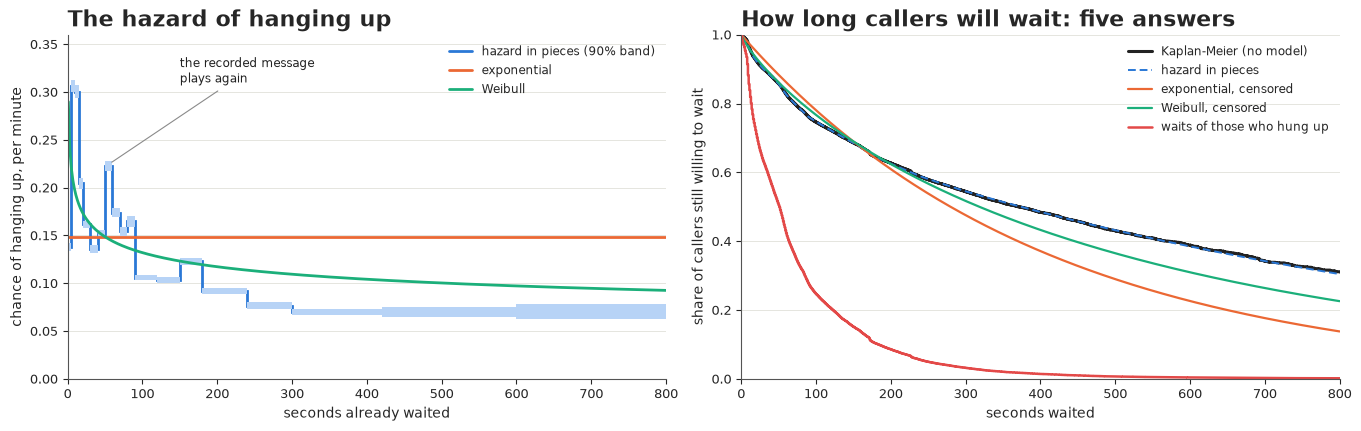

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
ax = axes[0]
mids = np.concatenate([(EDGES[:-2] + EDGES[1:-1]) / 2, [700]])
plot_edges = np.concatenate([EDGES[:-1], [800]])
lo, hi = np.quantile(HAZ, [0.05, 0.95], axis=0) * 60
ax.stairs(HAZ.mean(0) * 60, plot_edges, color=BLUE, lw=2, label="hazard in pieces (90% band)", baseline=None)
ax.fill_between(np.repeat(plot_edges, 2)[1:-1], np.repeat(lo, 2), np.repeat(hi, 2), color="#b7d3f6", lw=0)
tt = np.linspace(1, 800, 400)
ax.plot(tt, np.full_like(tt, RATE_EXP * 60), color=ORANGE, lw=2, label="exponential")
ax.plot(tt, 60 * K_WEI / SC_WEI * (tt / SC_WEI) ** (K_WEI - 1), color=AQUA, lw=2, label="Weibull")
ax.set_ylim(0, 0.36)
ax.set_xlim(0, 800)
ax.set_xlabel("seconds already waited")
ax.set_ylabel("chance of hanging up, per minute")
ax.legend(frameon=False, fontsize=8.5)
ax.annotate("the recorded message\nplays again", (56, 0.225), (150, 0.31), fontsize=8.5, color=INK,
            arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_title("The hazard of hanging up", loc="left")
tidy(ax)

ax = axes[1]
order = np.argsort(T)
ts, idx = np.unique(T[order], return_index=True)
at_risk = len(T) - idx
d_ev = np.add.reduceat(E[order].astype(float), idx)
km = np.cumprod(1 - d_ev / at_risk)
ax.step(ts, km, where="post", color=INK, lw=2.2, label="Kaplan-Meier (no model)")
ax.plot(tt, survival_pieces(HAZ.mean(0), tt), color=BLUE, lw=1.4, ls=(0, (4, 2)), label="hazard in pieces")
ax.plot(tt, np.exp(-RATE_EXP * tt), color=ORANGE, lw=1.6, label="exponential, censored")
ax.plot(tt, np.exp(-(tt / SC_WEI) ** K_WEI), color=AQUA, lw=1.6, label="Weibull, censored")
ax.plot(np.sort(T[E]), 1 - np.arange(1, E.sum() + 1) / E.sum(), color=RED, lw=1.8, label="waits of those who hung up")
ax.set_xlim(0, 800)
ax.set_ylim(0, 1)
ax.set_xlabel("seconds waited")
ax.set_ylabel("share of callers still willing to wait")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("How long callers will wait: five answers", loc="left")
tidy(ax);

The red curve is the naive answer. It says that half of all callers give up within a minute and almost
nobody lasts five. The black curve is the Kaplan-Meier estimate, which uses the served callers for
what they are, lower bounds, and assumes no shape at all: after a minute more than 80% are still
willing to wait, and after five minutes more than half. The mean wait of those who hung up was 79
seconds. The mean patience is somewhere between seven and eleven minutes, depending on what we assume
about callers who would have waited longer than anyone had to. A queue of callers who leave after 79
seconds and a queue of callers who stay seven minutes do not need the same roster.

Among the models that respect censoring, the exponential (the assumption inside Erlang's formula with
abandonment) has a constant hazard, and the Weibull a hazard that only falls. The left panel shows
what the data want: callers are most likely to leave in the first quarter of a minute, the hazard then
drops, rises again at about one minute, and declines slowly after that. Brown et al. (2005) found the
same two peaks and connect them to the recorded message that tells callers their place in the queue:
it plays when they join and again about a minute later, and it seems to prompt some of them to leave.
No two-parameter curve has two peaks. A hazard that is constant on each of 19 pieces of the clock
has, and it is still a small model: with events and exposure counted per piece, it is a Poisson
regression with 19 rows.

The Weibull's survival curve stays close to the Kaplan-Meier for the first three or four minutes,
which is where nearly all waits end, and for the queue that may be good enough. We keep the pieces
because they cost nothing and follow the data. Beyond ten minutes the hazard is one constant, fitted
to the few callers who waited that long: the mean patience depends on that tail, and the queue hardly
does.

> **The choice.** Patience has a hazard that is constant on 19 pieces of the clock, estimated from all
> queued calls with the served ones as censored. *Rejected:* the waits of those who hung up (they are
> the impatient minority: a mean of 79 seconds against 400 to 700), the exponential (flat hazard), the
> Weibull (no second peak). *Considered:* separate hazards for priority and regular customers, who
> differ in patience by a factor of two, and for call types; we pool them, because the simulator has a
> single queue. *What would change our mind:* patience that depends on the wait callers expect, so
> that a better-staffed centre faces less patient callers. Then the hazard measured in 1999 would not
> carry over to a different roster, and this is the weakest link in the chain.

## 5 · The queue: do the three models, put together, behave like the real call centre?

We now have calls, call lengths and patience. A queue turns them into waits and lost calls, and it
needs one more thing: the number of agents. Erlang's formulas do this step with algebra, under the
assumptions parts 2 to 4 have just rejected. We use a simulator, which makes no such demands. It
walks through a day event by event: a call arrives and takes a free agent, or joins the back of the
queue; an agent finishes and takes the caller at the front, unless that caller's patience ran out
first, in which case the call is lost and the next one is tried; on the hour the number of agents
changes. Forty lines of code, compiled by Numba, run a day of 1,700 calls in well under a
millisecond.

In [15]:
@njit
def simulate_day(arr, pat, ser, cap_edges, cap):
    """First come, first served, with hang-ups. arr: arrival times (sorted, seconds); pat: patience;
    ser: service time; cap[k] agents between cap_edges[k] and cap_edges[k + 1]. Returns each call's
    wait and whether it was served."""
    n = len(arr)
    wait = np.zeros(n)
    served = np.zeros(n, np.bool_)
    done = np.full(64, np.inf)            # when each busy agent finishes (inf = free)
    busy = 0
    queue = np.empty(n, np.int64)
    head = tail = 0
    i = k = 0
    c = cap[0]
    while True:
        t_arr = arr[i] if i < n else np.inf
        j = np.argmin(done)
        t_done = done[j]
        t_cap = cap_edges[k + 1] if k + 1 < len(cap) else np.inf
        t = min(t_arr, t_done, t_cap)
        if t == np.inf:
            break
        if t_done <= t:                   # an agent finishes
            done[j] = np.inf
            busy -= 1
        elif t_cap <= t:                  # the roster changes on the hour
            k += 1
            c = cap[k]
        else:                             # a call arrives
            queue[tail] = i
            tail += 1
            i += 1
        while busy < c and head < tail:   # free agents take the front of the queue
            m = queue[head]
            head += 1
            if arr[m] + pat[m] < t:       # this caller has already hung up
                wait[m] = pat[m]
                continue
            wait[m] = t - arr[m]
            served[m] = True
            for s in range(64):
                if done[s] == np.inf:
                    done[s] = t + ser[m]
                    break
            busy += 1
    for z in range(head, tail):
        wait[queue[z]] = pat[queue[z]]
    return wait, served


EDGE_S = np.arange(7, 25) * 3600.0
TICK = np.arange(7 * 3600, 24 * 3600, 10.0)                  # the day in 10-second ticks
tick_hour = (TICK // 3600).astype(int) - 7


def in_progress(start, length):
    """How many intervals [start, start + length) cover each tick."""
    up = np.searchsorted(TICK, start, side="left")
    down = np.searchsorted(TICK, start + length, side="left")
    x = np.zeros(len(TICK) + 1)
    np.add.at(x, up, 1)
    np.add.at(x, down, -1)
    return np.cumsum(x)[:-1]

A simulator is a model like any other, and it has to earn trust the same way: by reproducing data.
The test is a replay. We take the real days of 1999, keep each call's real arrival time and type,
draw its length and its caller's patience from the models of parts 3 and 4, give the simulator the
number of agents on duty, and compare the simulated share of lost calls and the simulated waits with
what happened. (For the replay the service model includes the hang-ups by agents, because in 1999
they happened.)

The data do not include the roster. The nearest thing is a count of **heads**: how many different
agents took at least one call in each hour.

### Failure: heads on the roster

In [16]:
by_day = {d: g for d, g in reg.groupby("date")}
rows = []
for d, g in by_day.items():
    sv_d = g[(~g["lost"]) & g["ser_start_s"].notna()]
    busy_now = in_progress(sv_d["ser_start_s"].to_numpy(float), sv_d["ser_time"].to_numpy(float))
    qq = g[g["q_start_s"].notna()]
    waiting_now = in_progress(qq["q_start_s"].to_numpy(float), qq["q_time"].to_numpy(float))
    heads = sv_d.groupby("hour")["agent"].nunique().reindex(HOURS, fill_value=0).to_numpy()
    for i in range(17):
        m = tick_hour == i
        mq = m & (waiting_now > 0)
        rows.append((d, HOURS[i], heads[i], busy_now[m].mean(),
                     busy_now[mq].mean() if mq.sum() >= 6 else np.quantile(busy_now[m], 0.9)))
cap = pd.DataFrame(rows, columns=["date", "hour", "heads", "busy", "answering"])
HEADS = cap.pivot(index="date", columns="hour", values="heads")
ANSWERING = cap.pivot(index="date", columns="hour", values="answering")

HAZ_MEAN = HAZ.mean(0)


def replay(capacity, dates, seed, S):
    """Real arrivals and call types, modelled service (posterior means of S) and patience, given agents."""
    gen = np.random.default_rng(seed)
    mu_, sig_, by_m, by_h = S["mu"].mean(0), S["sigma"].mean(0), S["month_eff"].mean(0), S["hour_eff"].mean(0)
    res = []
    for d in dates:
        g = by_day[d]
        ty = np.maximum(pd.Index(TYPES).get_indexer(g["type"]), 0)
        ser = np.exp(mu_[ty] + by_m[d.month - 1] + by_h[g["hour"].to_numpy() - 7] + sig_[ty] * gen.normal(size=len(g)))
        hung = gen.random(len(g)) < S["w_short"][:, int(d.month > 10)].mean()
        ser[hung] = np.exp(S["mu_short"].mean() + S["sigma_short"].mean() * gen.normal(size=hung.sum()))
        wait, ok = simulate_day(g["t"].to_numpy(), draw_patience(HAZ_MEAN, len(g), gen), ser, EDGE_S,
                                np.maximum(capacity.loc[d].to_numpy(), 1).astype(np.int64))
        res.append((d, 1 - ok.mean(), wait.mean(), (wait > 0).mean(), wait, ok))
    return pd.DataFrame(res, columns=["date", "lost", "wait", "queued", "waits", "served"]).set_index("date")


actual = reg.groupby("date").agg(lost=("lost", "mean"), wait=("q_time", "mean"), queued=("q_time", lambda s: (s > 0).mean()))
first_half = [d for d in days if d.month <= 6]
second_half = [d for d in days if d.month > 6]
sim_heads = replay(HEADS, list(days), seed=1, S=SER)
print(f"all {len(days)} days, heads as capacity: simulated calls lost {sim_heads['lost'].mean():.1%}, "
      f"mean wait {sim_heads['wait'].mean():.0f} s  |  actual: {actual['lost'].mean():.1%}, {actual['wait'].mean():.0f} s")
print("mean over days and hours: heads", round(HEADS.to_numpy().mean(), 1), "| agents busy at a random moment",
      round(cap["busy"].mean(), 1), "| agents busy while someone is waiting", round(ANSWERING.to_numpy().mean(), 1))

all 244 days, heads as capacity: simulated calls lost 3.8%, mean wait 14 s  |  actual: 15.1%, 62 s
mean over days and hours: heads 8.0 | agents busy at a random moment 4.1 | agents busy while someone is waiting 4.7


The simulated call centre is a calm place: it loses one call in twenty-five, where the real one lost
four times as many, and its callers wait a quarter as long. One of the links is badly wrong, and the
printed line says which. On average eight different agents handle calls in an hour, but only about
four are on a call at a random moment, and fewer than five even at moments when callers are queuing.
An agent on the roster is not an agent on the phone: people start and end shifts inside the hour, take
breaks, write up the call they have just finished, and look after the internet customers in the next
room.

This is the first orange arrow of the route map. Nothing in parts 2 to 4 was wrong. The chain was
missing a link that nobody would have listed at the start: **how many agents are really answering**.

### The link we had not planned: effective capacity

The data can tell us, indirectly. When somebody is waiting, every agent who is able to take a call
is on one. So the number of calls in progress, at the moments when the queue is not empty, measures
the capacity callers actually met. We compute it for every day and hour from the start and end of
each service.

It is still a little too low, because an agent who finishes a call needs a few seconds to pick up the
next one, and during those seconds the count misses them. We allow for that with one multiplier
$\kappa$, the only free parameter of the simulator. We tune it on the first half of the year so that
the simulated share of lost calls matches the real one, and then keep our hands off: the second half
of the year is the test, and so are the waits, which $\kappa$ was never tuned to.

In [17]:
U = pd.DataFrame(np.random.default_rng(5).random(ANSWERING.shape), index=ANSWERING.index, columns=ANSWERING.columns)
KAPPAS = np.arange(0.95, 1.31, 0.05)


def effective(kappa):
    return np.floor(kappa * ANSWERING + U)       # round up or down at random, so 6.4 agents is 6 or 7


def tune_and_test(S, label):
    lost_k = np.array([replay(effective(kp), first_half, seed=2, S=S)["lost"].mean() for kp in KAPPAS])
    kappa = float(np.interp(actual.loc[first_half, "lost"].mean(), lost_k[::-1], KAPPAS[::-1]))
    sim = replay(effective(kappa), list(days), seed=3, S=S)
    r = np.corrcoef(sim.loc[second_half, "lost"], actual.loc[second_half, "lost"])[0, 1]
    err = (sim.loc[second_half, "lost"] - actual.loc[second_half, "lost"]).abs().mean()
    print(f"{label}: kappa = {kappa:.2f} (first half: simulated {sim.loc[first_half, 'lost'].mean():.3f}, "
          f"actual {actual.loc[first_half, 'lost'].mean():.3f}); test days: correlation {r:.2f}, "
          f"mean absolute error {err:.3f}")
    return kappa, sim


def test_table(sims):
    out = pd.DataFrame({"actual": actual.loc[second_half].mean(),
                        **{k: v.loc[second_half, ["lost", "wait", "queued"]].mean() for k, v in sims.items()}}).T
    out.columns = ["calls lost", "mean wait (s)", "share who wait"]
    return out.round(3)


kappa_1, sim_1 = tune_and_test(SER, "service model of part 3")
print(f"\nsecond half of the year ({len(second_half)} days the tuning did not see):")
print(test_table({"simulated, heads": sim_heads, "simulated, effective capacity": sim_1}).to_string())

service model of part 3: kappa = 1.02 (first half: simulated 0.165, actual 0.164); test days: correlation 0.81, mean absolute error 0.056

second half of the year (127 days the tuning did not see):
                               calls lost  mean wait (s)  share who wait
actual                              0.138         59.904           0.585
simulated, heads                    0.037         13.662           0.197
simulated, effective capacity       0.186         79.179           0.656


### Failure again: the second half of the year

Measured capacity brings the simulator into the right region, and on the days it was tuned on it
matches by construction. On the test days it does not: it loses 19% of calls where the real centre
lost 14%, and its callers wait a third longer. A model tuned in spring is too gloomy about autumn.
Before blaming the tuning we look at where the error sits, by month and by hour of the day.

In [18]:
real = served[served["ser_time"] >= 10]                    # leave the agents' hang-ups out of the averages


def error_by(key, sim):
    """Simulated and actual share of calls lost, and how long real calls ran, by month or by hour."""
    all_key = np.concatenate([by_day[d][key].to_numpy() for d in days])
    lost_sim = 1 - pd.Series(np.concatenate(sim["served"].to_numpy())).groupby(all_key).mean()
    out = pd.DataFrame({"actual lost": reg.groupby(key)["lost"].mean(), "simulated lost": lost_sim})
    out["simulated minus actual"] = out["simulated lost"] - out["actual lost"]
    out["call length vs average"] = real.groupby(key)["ser_time"].mean() / real["ser_time"].mean() - 1
    return out


for key in ("month", "hour"):
    tab = error_by(key, sim_1)
    print(tab.round(3).T.to_string())
    print(f"correlation between the simulator's error and the call length, by {key}: "
          f"{np.corrcoef(tab['simulated minus actual'], tab['call length vs average'])[0, 1]:.2f}\n")

                           1      2      3      4      5      6      7      8      9      10     11     12
actual lost             0.109  0.132  0.245  0.206  0.200  0.134  0.197  0.193  0.090  0.063  0.145  0.165
simulated lost          0.129  0.156  0.232  0.147  0.193  0.151  0.216  0.229  0.156  0.149  0.190  0.194
simulated minus actual  0.020  0.024 -0.012 -0.059 -0.007  0.017  0.019  0.036  0.065  0.086  0.045  0.028
call length vs average -0.044 -0.065 -0.006  0.137  0.069  0.003 -0.011 -0.034  0.022 -0.069 -0.016  0.044
correlation between the simulator's error and the call length, by month: -0.70

                           7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
actual lost             0.071  0.110  0.175  0.207  0.174  0.145  0.149  0.163  0.232  0.198  0.179  0.140  0.095  0.080  0.103  0.143  0.109
simulated lost          0.174  0.141  0.141  0.187  0.167  0.148  0.170  0.163  0.172  0.217  0.228  

The error has a pattern, in the calendar and on the clock. By month, the simulator loses too few
calls in April and too many from August to November. By hour, it is close from 9:00 to 16:00 (short at
15:00) and far too gloomy at 7:00 and from 17:00 on. The last row of each table is how long real calls ran
in that month or hour against the average, and it mirrors the error: April's calls were 14% longer
than average and October's 7% shorter; calls at 15:00 were 15% longer and calls at 23:00 19% shorter.
The correlation between the two rows is -0.7 by month and -0.9 by hour. The service model of part 3
knows the type of a call and nothing about when it was made. (Brown et al. show the same pattern over
the day for regular calls.) In a queue that runs close to its capacity, a tenth more work is the
difference between a bad month and a good one.

This is the second orange arrow, and it leads back to part 3. Nothing we looked at there could have
shown the problem, because we had pooled the year and the day. The repair is two more terms on the
log of the call length, a month effect and an hour effect, shared by all call types and shrunk towards
zero. The calls no longer collapse to 12,000 rows, so this fit is the slowest step of the notebook,
about a minute and a half.

In [19]:
SER = fit_service(drift=True)
eff_m, eff_h = 100 * np.expm1(SER["month_eff"]), 100 * np.expm1(SER["hour_eff"])
print("\ncall length against the average, percent:")
print("  by month:", " ".join(f"{m_} {v:+.0f}" for m_, v in zip("Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split(), eff_m.mean(0))))
print("  by hour: ", " ".join(f"{h}h {v:+.0f}" for h, v in zip(HOURS, eff_h.mean(0))))
MEAN_SERVICE = mean_service(SER)
print("mean real call by hour on the target day (s):", MEAN_SERVICE.round(0))

KAPPA, sim_eff = tune_and_test(SER, "service model with month and hour")
PHI = np.nanmedian((KAPPA * ANSWERING / HEADS.where(HEADS > 0)).to_numpy(), axis=0)   # by hour of the day
print(f"\nsecond half of the year ({len(second_half)} days the tuning did not see):")
print(test_table({"simulated, heads": sim_heads, "simulated, effective capacity": sim_1,
                  "simulated, effective capacity, drifting calls": sim_eff}).to_string())
print("\nagents answering per head on the roster, by hour (median over days):", PHI.round(2),
      f"| over the day {np.nanmedian((KAPPA * ANSWERING / HEADS.where(HEADS > 0)).to_numpy()):.2f}")

317,481 calls in 150,320 weighted rows; divergences: 0; max r_hat 1.006
                   mean     sd   ess_bulk  r_hat
mu[PS]            4.855  0.002   8223.822  1.002
mu[NW]            4.272  0.005   8569.700  1.002
mu[NE]            5.168  0.006   7353.366  1.001
mu[IN]            5.391  0.011   9057.089  1.000
mu[TT]            3.655  0.017   9281.117  1.001
mu[PE]            5.283  0.028  10598.548  1.002
sigma[PS]         0.847  0.001   7803.100  1.002
sigma[NW]         0.956  0.004   8643.093  1.002
sigma[NE]         0.956  0.004  10228.942  1.002
sigma[IN]         1.174  0.007   9311.255  1.000
sigma[TT]         1.562  0.013  11437.548  0.999
sigma[PE]         0.848  0.020   9818.908  1.001
mu_short          1.306  0.008   5220.529  1.003
sigma_short       0.766  0.006   5764.830  1.001
w_short[Jan-Oct]  0.056  0.001   6426.010  1.001
w_short[Nov-Dec]  0.007  0.000   8437.517  1.000
s_month           0.073  0.018   9133.254  1.001
s_hour            0.099  0.020   7706.072  1.0

service model with month and hour: kappa = 1.08 (first half: simulated 0.163, actual 0.164); test days: correlation 0.81, mean absolute error 0.039

second half of the year (127 days the tuning did not see):
                                               calls lost  mean wait (s)  share who wait
actual                                              0.138         59.904           0.585
simulated, heads                                    0.037         13.662           0.197
simulated, effective capacity                       0.186         79.179           0.656
simulated, effective capacity, drifting calls       0.155         62.813           0.589

agents answering per head on the roster, by hour (median over days): [0.48 0.59 0.75 0.77 0.7  0.65 0.61 0.65 0.66 0.62 0.62 0.6  0.6  0.57
 0.61 0.67 0.68] | over the day 0.64


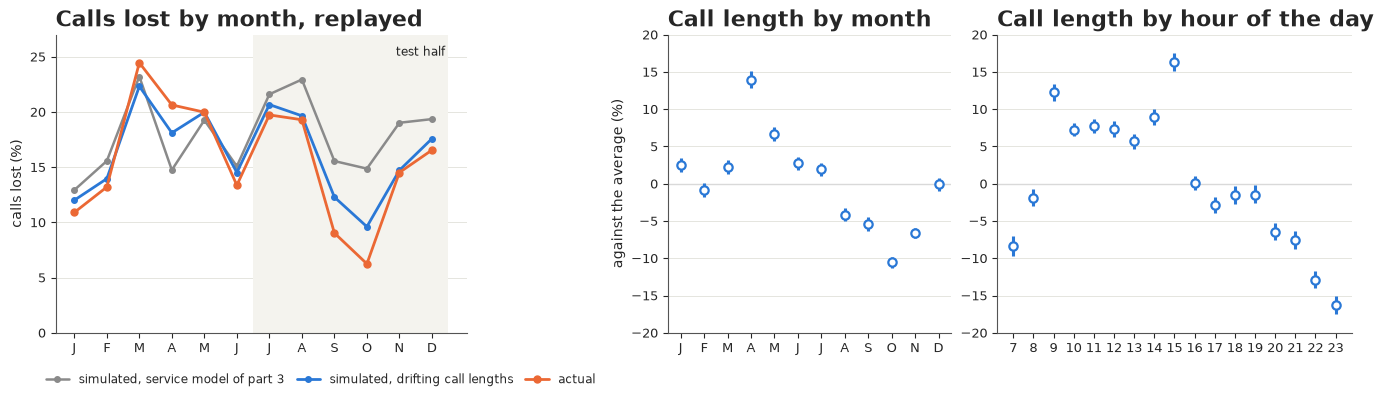

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), gridspec_kw={"width_ratios": [1.45, 1, 1.25]})
ax = axes[0]
mths = np.arange(1, 13)
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
ax.axvspan(6.5, 12.5, color="#f4f3ee", lw=0)
ax.text(12.4, 26, "test half", ha="right", va="top", fontsize=8.5, color=INK)
ax.plot(mths, error_by("month", sim_1)["simulated lost"] * 100, "o-", color=MUTED, lw=1.8, ms=4, label="simulated, service model of part 3")
ax.plot(mths, error_by("month", sim_eff)["simulated lost"] * 100, "o-", color=BLUE, lw=2, ms=4, label="simulated, drifting call lengths")
ax.plot(mths, reg.groupby("month")["lost"].mean() * 100, "o-", color=ORANGE, lw=2, ms=5, label="actual")
ax.set_xticks(mths, MONTHS)
ax.set_ylabel("calls lost (%)")
ax.set_ylim(0, 27)
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=3, bbox_to_anchor=(-0.05, -0.1), columnspacing=1.0)
ax.set_title("Calls lost by month, replayed", loc="left")
tidy(ax)
for ax, eff_, ticks, labels, title in ((axes[1], eff_m, mths, MONTHS, "Call length by month"),
                                       (axes[2], eff_h, HOURS, [f"{h}" for h in HOURS], "Call length by hour of the day")):
    lo, hi = np.quantile(eff_, [0.05, 0.95], axis=0)
    ax.axhline(0, color=LIGHT, lw=1)
    ax.vlines(ticks, lo, hi, color=BLUE, lw=2.2)
    ax.plot(ticks, eff_.mean(0), "o", ms=6, color="white", mec=BLUE, mew=1.6)
    ax.set_xticks(ticks, labels)
    ax.set_ylim(-20, 20)
    ax.set_title(title, loc="left")
    tidy(ax)
axes[1].set_ylabel("against the average (%)");

that day: actual lost 17.1%, simulated 22.5%
share of the day's 5-minute steps where the real queue is inside the 90% band: 0.83


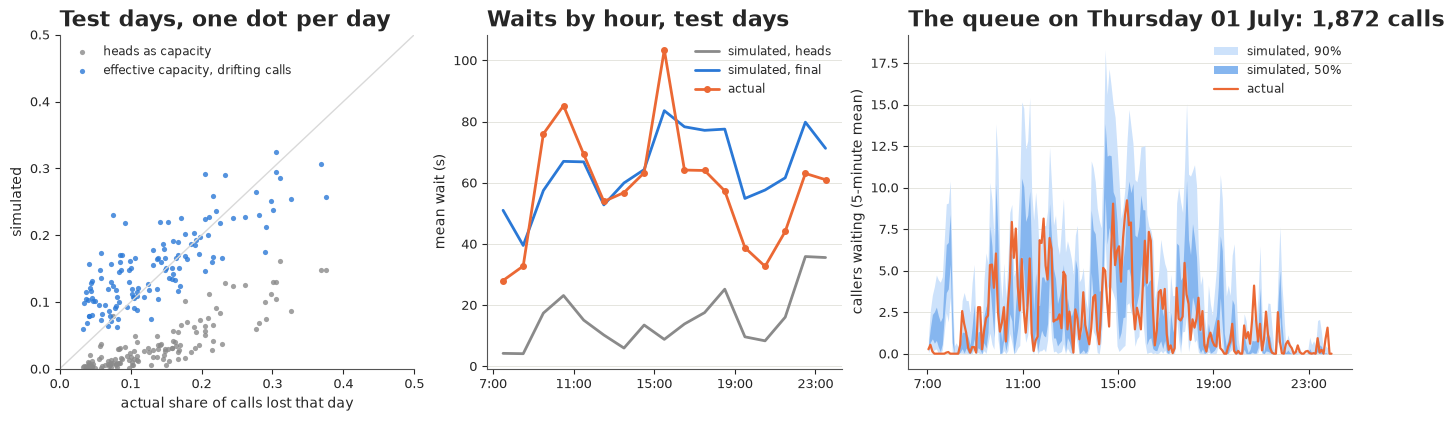

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1), gridspec_kw={"width_ratios": [1, 1, 1.25]})
ax = axes[0]
ax.plot([0, 0.5], [0, 0.5], color=LIGHT, lw=1)
ax.scatter(actual.loc[second_half, "lost"], sim_heads.loc[second_half, "lost"], s=14, color=MUTED, lw=0, alpha=0.8,
           label="heads as capacity")
ax.scatter(actual.loc[second_half, "lost"], sim_eff.loc[second_half, "lost"], s=14, color=BLUE, lw=0, alpha=0.8,
           label="effective capacity, drifting calls")
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 0.5)
ax.set_xlabel("actual share of calls lost that day")
ax.set_ylabel("simulated")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Test days, one dot per day", loc="left")
tidy(ax, grid=None)

ax = axes[1]
test = reg[reg["date"].isin(second_half)]
hour_of = np.concatenate([by_day[d]["hour"].to_numpy() for d in second_half])
for sim, colour, label in ((sim_heads, MUTED, "simulated, heads"), (sim_eff, BLUE, "simulated, final")):
    w_all = np.concatenate(sim.loc[second_half, "waits"].to_numpy())
    ax.plot(HOURS + 0.5, pd.Series(w_all).groupby(hour_of).mean().to_numpy(), color=colour, lw=2, label=label)
ax.plot(HOURS + 0.5, test.groupby("hour")["q_time"].mean().to_numpy(), "o-", color=ORANGE, lw=2, ms=4, label="actual")
ax.set_xticks(range(7, 25, 4), [f"{h}:00" for h in range(7, 25, 4)])
ax.set_ylabel("mean wait (s)")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Waits by hour, test days", loc="left")
tidy(ax)

ax = axes[2]
calls_per_day = pd.Series({d: len(by_day[d]) for d in second_half})
show = calls_per_day.sort_values().index[int(0.9 * len(second_half))]       # a busy test day
g = by_day[show]
qq = g[g["q_start_s"].notna()]
five = lambda v: v.reshape(-1, 30).mean(1)                                  # 10-second ticks to 5-minute means
paths = np.array([five(in_progress(g["t"].to_numpy(), replay(effective(KAPPA), [show], seed=100 + r_, S=SER)["waits"].iloc[0]))
                  for r_ in range(150)])
xs = five(TICK) / 3600
ax.fill_between(xs, *np.quantile(paths, [0.05, 0.95], axis=0), color="#cde2fb", lw=0, label="simulated, 90%")
ax.fill_between(xs, *np.quantile(paths, [0.25, 0.75], axis=0), color="#86b6ef", lw=0, label="simulated, 50%")
ax.plot(xs, five(in_progress(qq["q_start_s"].to_numpy(float), qq["q_time"].to_numpy(float))), color=ORANGE, lw=1.6,
        label="actual")
ax.set_xticks(range(7, 25, 4), [f"{h}:00" for h in range(7, 25, 4)])
ax.set_ylabel("callers waiting (5-minute mean)")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title(f"The queue on {show:%A %d %B}: {len(g):,} calls", loc="left")
tidy(ax);
print(f"that day: actual lost {actual.loc[show, 'lost']:.1%}, simulated {sim_eff.loc[show, 'lost']:.1%}")
inside = np.mean((five(in_progress(qq["q_start_s"].to_numpy(float), qq["q_time"].to_numpy(float))) >= np.quantile(paths, 0.05, axis=0))
                 & (five(in_progress(qq["q_start_s"].to_numpy(float), qq["q_time"].to_numpy(float))) <= np.quantile(paths, 0.95, axis=0)))
print(f"share of the day's 5-minute steps where the real queue is inside the 90% band: {inside:.2f}")

With call lengths that drift, the multiplier settles at $\kappa = 1.08$ and the test half reads: 15.5%
of calls lost against the real 13.8%, a mean wait of 63 seconds against 60, and 59% of callers having
to wait against 58.5%. Only the first of the three was tuned, and only on the other half of the year.
In the monthly figure the blue line now follows the orange one through April and the autumn. Day by
day (left panel above) the simulated and real shares of lost calls have a correlation of 0.8, where
heads as capacity put nearly every day close to zero. The right panel replays one busy test day 150
times: the real queue builds and drains at the hours the simulated ones do, and stays inside the 90%
band for about five steps in six.

Two weaknesses remain, and both matter for what follows. The simulator is still nearly two points too
gloomy on the test half, mostly in September and October, the calmest months. And the middle panel
shows that the hours are not all equally good: the simulated waits follow the real ones through the
working day, miss part of the peaks at 10:00 and 15:00, and run above them early in the morning and
late in the evening. Both point at the
capacity measure. We count agents at the moments when someone is waiting, and in a quiet hour with
three agents on, somebody waits precisely when one of the three has stepped away. A simulator with a
fixed number of agents per hour has no five-minute gaps in it. The consequence is specific. The queue
logic and the two models that feed it are tested, and hold. The conversion from agents answering to
heads on a roster, 0.64 over the day and between 0.5 and 0.8 by hour, is the least certain number in
this notebook, and probably too low in the quiet hours.

> **The choice.** A discrete-event simulator; capacity measured as the calls in progress while
> somebody waits, with one multiplier tuned on half the year; call lengths that drift with the month
> and the hour. *Rejected:* Erlang's formulas as the engine (they need the assumptions parts 2 to 4
> threw out; they come back in part 6 as rivals), heads on the roster as capacity (a calm call centre
> that never existed), and a service model blind to the calendar and the clock. *Considered:* a
> multiplier for each part of the day, which would hide the evening problem without explaining it;
> counting an agent as on duty between calls a few minutes apart, a second measure with a free
> parameter of its own, which did no better when we tried it; and replaying each call with its real
> length, which matches the days more closely because it uses more of the truth, and tests less of
> the chain. *What would change our mind:* the bank's shift records. With them capacity would be data
> and not an inference.

## 6 · The decision: how many agents, hour by hour?

Everything is now in place for the manager's question. We generate 300 Sundays at December's level
that have not happened. Each takes one draw from the posterior of every model: a day effect, a tilt
and the hour-to-hour noise from part 2; a type and a length for every call from part 3, with December's
month effect, the hour's effect and no hang-ups by agents; a patience for every caller from part 4.
The simulator of part 5 then plays each day against a roster.

A roster is 17 numbers, one per hour, and we need a sensible family of them with a single dial. Queueing
theory supplies one. The work that arrives in an hour, measured in agents, is the arrival rate times
the mean call length, $R_h = \lambda_h \, \mathrm{E}[S_h]$: about nine agents' worth at the 10:00
peak. A roster of exactly $R_h$ has no slack for chance, and the square-root staffing rule (Halfin and
Whitt 1981) adds a margin in proportion to its square root, $c_h = \lceil R_h + \beta \sqrt{R_h}
\rceil$. One number $\beta$ then sets the quality of service for the whole day. Negative values run
the centre short and rely on callers giving up; large ones buy idle agents. Rosters here count
**agents answering**, the unit in which the simulator was tested; heads return at the end.

In [22]:
gen_dec = np.random.default_rng(RANDOM_SEED + 6)
MEAN_SHORT = float(np.exp(SER["mu_short"] + SER["sigma_short"] ** 2 / 2).mean())
W_KEPT = float(SER["w_short"][:, 0].mean())
MEAN_SERVICE_KEPT = (1 - W_KEPT) * MEAN_SERVICE + W_KEPT * MEAN_SHORT    # a planner who takes hang-ups as service
MIX_CUM = np.cumsum(MIX, axis=1)


def make_days(n, arrivals="busy + tilted days", shape="lognormal", hangups="set aside", patience="pieces", seed=0):
    """n days that have not happened: arrival times, patience and service time of every call."""
    gen = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        j = gen.integers(N_POST)
        if arrivals == "Poisson":
            cnt = gen.poisson(LAM_MEAN)
        else:
            cnt = new_day_counts(new_day_rates(j, gen=gen), j, gen)
        h = np.repeat(np.arange(17), cnt)
        arr = np.sort((HOURS[h] + gen.random(len(h))) * 3600.0)
        ty = (gen.random(len(h))[:, None] > MIX_CUM[h]).sum(1).clip(max=5)
        if shape == "exponential":
            ser = gen.exponential((MEAN_SERVICE if hangups == "set aside" else MEAN_SERVICE_KEPT)[h])
        else:
            ser = np.exp(SER["mu"][j, ty] + SER["month_eff"][j, 11] + SER["hour_eff"][j, h]
                         + SER["sigma"][j, ty] * gen.normal(size=len(h)))
            if hangups == "kept":
                hung = gen.random(len(h)) < SER["w_short"][j, 0]
                ser[hung] = np.exp(SER["mu_short"][j] + SER["sigma_short"][j] * gen.normal(size=hung.sum()))
        if patience == "pieces":
            pat_ = draw_patience(HAZ[j], len(h), gen)
        else:
            pat_ = gen.exponential(NAIVE_MEAN if patience == "naive" else 1 / RATE_EXP, len(h))
        out.append((arr, pat_, ser))
    return out


def evaluate(day_list, capacity):
    """Calls, calls lost, total wait and calls answered within 20 s, per day."""
    res = np.empty((len(day_list), 4))
    for i, (arr, pat_, ser) in enumerate(day_list):
        c = capacity if capacity.ndim == 1 else capacity[i]
        wait, ok = simulate_day(arr, pat_, ser, EDGE_S, np.maximum(c, 1).astype(np.int64))
        res[i] = len(arr), (~ok).sum(), wait.sum(), (ok & (wait <= 20)).sum()
    return res


LOAD = LAM_MEAN * MEAN_SERVICE / 3600                       # work arriving per hour, in agents


def roster(beta):
    return np.maximum(1, np.ceil(LOAD + beta * np.sqrt(LOAD))).astype(np.int64)


t0 = time.time()
future = make_days(300, seed=RANDOM_SEED)
BETAS = np.arange(-1.0, 2.26, 0.25)
front = np.array([evaluate(future, roster(b)) for b in BETAS])           # beta x day x 4
agent_hours = np.array([roster(b).sum() for b in BETAS])
lost_day = front[:, :, 1] / front[:, :, 0]
lost_all = front[:, :, 1].sum(1) / front[:, :, 0].sum(1)
wait_all = front[:, :, 2].sum(1) / front[:, :, 0].sum(1)
quick_all = front[:, :, 3].sum(1) / front[:, :, 0].sum(1)
print(f"{len(BETAS) * len(future):,} simulated days in {time.time() - t0:.1f} s")
print("work arriving by hour, in agents:", LOAD.round(1))
frontier = pd.DataFrame({"beta": BETAS, "agent-hours": agent_hours, "peak agents": [roster(b).max() for b in BETAS],
                         "calls lost": lost_all, "lost, worst day in 10": np.quantile(lost_day, 0.9, axis=1),
                         "mean wait (s)": wait_all, "answered in 20 s": quick_all})
print(frontier.round(3).to_string(index=False))

4,200 simulated days in 1.5 s
work arriving by hour, in agents: [2.1 4.8 8.5 9.4 8.1 7.2 7.4 8.1 8.6 6.6 5.1 4.6 3.9 3.3 3.4 3.  2.2]
 beta  agent-hours  peak agents  calls lost  lost, worst day in 10  mean wait (s)  answered in 20 s
-1.00           65            7       0.369                  0.458        180.341             0.136
-0.75           76            8       0.289                  0.375        132.443             0.225
-0.50           85            8       0.232                  0.315        101.233             0.310
-0.25           93            9       0.188                  0.267         78.936             0.392
 0.00          106           10       0.133                  0.196         52.605             0.518
 0.25          115           11       0.102                  0.161         39.155             0.602
 0.50          122           11       0.083                  0.132         30.843             0.662
 0.75          135           12       0.056                  0.092

In [23]:
def erlang_c_late(lam, mu, c, t=20.0):
    """Erlang C: share of callers who wait more than t seconds, if nobody ever hangs up."""
    load = lam / mu
    if load >= c:
        return 1.0
    b = 1.0
    for k_ in range(1, c + 1):
        b = load * b / (k_ + load * b)
    return b / (1 - (load / c) * (1 - b)) * np.exp(-(c * mu - lam) * t)


def erlang_a_lost(lam, mu, theta, c, kmax=600):
    """Erlang A: share of callers who hang up, with exponential patience of rate theta."""
    n = np.arange(1, c + kmax + 1)
    logp = np.concatenate([[0.0], np.cumsum(np.log(lam / (np.minimum(n, c) * mu + np.maximum(n - c, 0) * theta)))])
    p = np.exp(logp - logp.max())
    p /= p.sum()
    return theta * (p * np.maximum(np.arange(c + kmax + 1) - c, 0)).sum() / lam


def smallest(rule):
    return np.array([next(c for c in range(1, 60) if rule(h, c)) for h in range(17)])


lam_s, mu_s = LAM_MEAN / 3600, 1 / MEAN_SERVICE
RIVALS = {
    "Erlang C, 80% answered in 20 s": smallest(lambda h, c: erlang_c_late(lam_s[h], mu_s[h], c) <= 0.2),
    "Erlang A, 5% lost, naive patience": smallest(lambda h, c: erlang_a_lost(lam_s[h], mu_s[h], 1 / NAIVE_MEAN, c) <= 0.05),
    "Erlang A, 5% lost, censored patience": smallest(lambda h, c: erlang_a_lost(lam_s[h], mu_s[h], RATE_EXP, c) <= 0.05),
}
dec_cap = np.floor(KAPPA * ANSWERING.loc[dec_sundays] + U.loc[dec_sundays]).mean(0).round().to_numpy().astype(int)
RIVALS["the bank's December Sundays"] = dec_cap
rival_rows = {}
for name, c in RIVALS.items():
    r = evaluate(future, c)
    rival_rows[name] = {"agent-hours": c.sum(), "peak agents": c.max(), "calls lost": r[:, 1].sum() / r[:, 0].sum(),
                        "lost, worst day in 10": np.quantile(r[:, 1] / r[:, 0], 0.9),
                        "mean wait (s)": r[:, 2].sum() / r[:, 0].sum(), "answered in 20 s": r[:, 3].sum() / r[:, 0].sum()}
rivals = pd.DataFrame(rival_rows).T
print(rivals.round(3).to_string())
print("\nactual December Sundays: calls", [len(by_day[d]) for d in dec_sundays], "lost",
      actual.loc[dec_sundays, "lost"].round(3).tolist())

i5 = int(np.argmax(lost_all <= 0.05))                    # the leanest roster that loses 5% or less on average
i5s = int(np.argmax(np.quantile(lost_day, 0.9, axis=1) <= 0.05))
print(f"\n5% on average: beta = {BETAS[i5]:.2f}, {agent_hours[i5]} agent-hours, roster {roster(BETAS[i5]).tolist()}")
print(f"5% on nine days in ten: beta = {BETAS[i5s]:.2f}, {agent_hours[i5s]} agent-hours, roster {roster(BETAS[i5s]).tolist()}")
print(f"in heads, with the hourly conversion of part 5: {np.ceil(roster(BETAS[i5]) / PHI).sum():.0f} and "
      f"{np.ceil(roster(BETAS[i5s]) / PHI).sum():.0f} head-hours; peak {np.ceil(roster(BETAS[i5]) / PHI).max():.0f} heads")

/var/folders/nw/92nd031j7p5d2bs8grpysp4w0000gn/T/ipykernel_44514/338373552.py:31: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  dec_cap = np.floor(KAPPA * ANSWERING.loc[dec_sundays] + U.loc[dec_sundays]).mean(0).round().to_numpy().astype(int)


                                      agent-hours  peak agents  calls lost  lost, worst day in 10  mean wait (s)  answered in 20 s
Erlang C, 80% answered in 20 s              146.0         13.0       0.039                  0.069         13.733             0.817
Erlang A, 5% lost, naive patience           150.0         13.0       0.035                  0.063         12.306             0.831
Erlang A, 5% lost, censored patience        131.0         12.0       0.064                  0.107         23.184             0.724
the bank's December Sundays                  99.0          9.0       0.166                  0.244         68.543             0.443

actual December Sundays: calls [1505, 2067, 1549, 1711] lost [0.098, 0.291, 0.072, 0.092]

5% on average: beta = 1.00, 144 agent-hours, roster [4, 8, 12, 13, 11, 10, 11, 11, 12, 10, 8, 7, 6, 6, 6, 5, 4]
5% on nine days in ten: beta = 1.50, 166 agent-hours, roster [5, 9, 13, 15, 13, 12, 12, 13, 14, 11, 9, 8, 7, 7, 7, 6, 5]
in heads, with the h

same roster: P(day loses more than 10%) = 0.03 with busy days, 0.00 with Poisson days; lost overall 0.041 vs 0.022


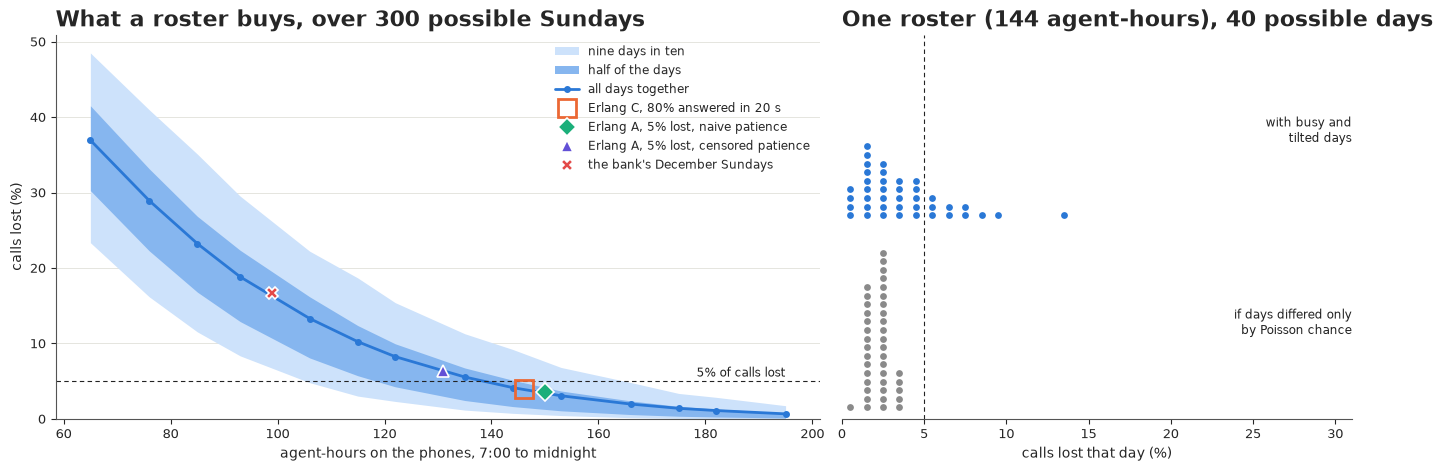

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.fill_between(agent_hours, *np.quantile(lost_day, [0.05, 0.95], axis=1) * 100, color="#cde2fb", lw=0,
                label="nine days in ten")
ax.fill_between(agent_hours, *np.quantile(lost_day, [0.25, 0.75], axis=1) * 100, color="#86b6ef", lw=0,
                label="half of the days")
ax.plot(agent_hours, lost_all * 100, "o-", color=BLUE, lw=2, ms=4, label="all days together")
ax.axhline(5, color=INK, lw=0.8, ls=(0, (4, 3)))
ax.text(agent_hours[-1], 5.6, "5% of calls lost", ha="right", fontsize=8.5, color=INK)
marks = {"Erlang C, 80% answered in 20 s": ("s", ORANGE), "Erlang A, 5% lost, naive patience": ("D", AQUA),
         "Erlang A, 5% lost, censored patience": ("^", VIOLET), "the bank's December Sundays": ("X", RED)}
for name, (marker, colour) in marks.items():
    hollow = marker == "s"                                # a ring, so that a marker underneath stays visible
    ax.plot(rivals.loc[name, "agent-hours"], rivals.loc[name, "calls lost"] * 100, marker, ms=13 if hollow else 9,
            color="none" if hollow else colour, mec=colour if hollow else "white", mew=2 if hollow else 1.2,
            label=name, ls="none", zorder=5)
ax.set_xlabel("agent-hours on the phones, 7:00 to midnight")
ax.set_ylabel("calls lost (%)")
ax.set_ylim(0, None)
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("What a roster buys, over 300 possible Sundays", loc="left")
tidy(ax)

ax = axes[1]
flat_days = make_days(300, arrivals="Poisson", seed=RANDOM_SEED)
r_flat = evaluate(flat_days, roster(BETAS[i5]))
edges_ = np.arange(0, 32, 1.0)
rows_ = [(r_flat[:, 1] / r_flat[:, 0], MUTED, "if days differed only\nby Poisson chance"),
         (lost_day[i5], BLUE, "with busy and\ntilted days")]
bins_ = [np.digitize(np.quantile(v * 100, (np.arange(40) + 0.5) / 40), edges_) for v, _, _ in rows_]
step_ = 0.85 / max(np.bincount(b).max() for b in bins_)             # the tallest stack fills its row
for k_, ((vals, colour, label), which) in enumerate(zip(rows_, bins_)):
    for b_ in np.unique(which):
        n_ = (which == b_).sum()
        ax.scatter(np.full(n_, edges_[b_ - 1] + 0.5), k_ + 0.06 + step_ * np.arange(n_), s=24, color=colour, lw=0)
    ax.text(31, k_ + 0.5, label, ha="right", va="center", fontsize=8.8, color=INK)
ax.axvline(5, color=INK, lw=0.8, ls=(0, (4, 3)))
ax.set_yticks([])
ax.set_xlim(0, 31)
ax.set_ylim(0, 2)
ax.set_xlabel("calls lost that day (%)")
ax.set_title(f"One roster ({agent_hours[i5]} agent-hours), 40 possible days", loc="left")
tidy(ax, grid=None)
ax.spines["left"].set_visible(False);
print(f"same roster: P(day loses more than 10%) = {(lost_day[i5] > 0.10).mean():.2f} with busy days, "
      f"{(r_flat[:, 1] / r_flat[:, 0] > 0.10).mean():.2f} with Poisson days; lost overall "
      f"{lost_all[i5]:.3f} vs {r_flat[:, 1].sum() / r_flat[:, 0].sum():.3f}")

In [25]:
calls_mean = front[0, :, 0].mean()
print("cheapest roster when a lost call costs as much as m minutes of an agent's time:")
for minutes in (2, 5, 10, 20, 40):
    cost = agent_hours + lost_all * calls_mean * minutes / 60
    b_ = int(np.argmin(cost))
    print(f"  m = {minutes:>2} min: {agent_hours[b_]} agent-hours (beta {BETAS[b_]:+.2f}), {lost_all[b_]:.1%} lost, "
          f"mean wait {wait_all[b_]:.0f} s")

cheapest roster when a lost call costs as much as m minutes of an agent's time:
  m =  2 min: 65 agent-hours (beta -1.00), 36.9% lost, mean wait 180 s
  m =  5 min: 76 agent-hours (beta -0.75), 28.9% lost, mean wait 132 s
  m = 10 min: 106 agent-hours (beta +0.00), 13.3% lost, mean wait 53 s
  m = 20 min: 135 agent-hours (beta +0.75), 5.6% lost, mean wait 20 s
  m = 40 min: 153 agent-hours (beta +1.25), 3.1% lost, mean wait 11 s


The frontier is the manager's menu. A roster equal to the arriving work ($\beta = 0$, 106
agent-hours) loses 13% of calls. Every further ten agent-hours buy less than the last: 135 agent-hours
lose 5.6%, 144 lose 4.1%, 166 lose 2%. The leanest roster of the family that loses 5% of calls or
fewer, all days together, is $\beta = 1$: 144 agent-hours, with 13 agents answering at the 10:00 peak
and 4 in the first and last hours.

**Where the bank was.** The red cross is the capacity we measured on the four December Sundays of
1999, about 99 agent-hours. The model says such a roster loses one call in six on a Sunday of this
kind. The four real ones lost 10%, 29%, 7% and 9%. The cost lines printed above read the same point
from the other side: a roster near 100 agent-hours is the cheapest one for a manager who values a lost
call at about ten minutes of an agent's time, and halving the loss is worth it only if a lost call is
worth twenty.

**The textbook formulas, judged by the full model.** Erlang C, with the common target of 80% of calls
answered within 20 seconds, asks for 146 agent-hours: almost exactly our roster. In the full model it
keeps its promise, with 82% answered in 20 seconds and 3.9% lost (the orange square, beside the green
diamond). That deserves a moment, because the formula assumes away the busy days of part 2 and
the hang-ups of part 4. The two errors pull in opposite directions. Ignoring busy days asks for too
few agents. Assuming that nobody ever leaves the queue asks for too many, because in the formula's
world an overloaded hour never recovers. Here they nearly cancel, and they need not. Erlang A adds
exponential patience, and is the better model on paper: it removes the second error and keeps the
first. With patience estimated properly (censored) it asks for 131 agent-hours, promises 5% lost and
loses 6.4%, with one day in ten above 10%. With the naive patience of 79 seconds it asks for 150, and
its mistake about patience pays for its mistake about arrivals.

**What busy days cost.** The right panel takes our 144 agent-hours and shows 40 possible days twice:
once from the arrival model of part 2, and once from a world with the same average demand in which
days differ only by Poisson chance. In the Poisson world the roster loses 2% of calls and no day is
far from that. With busy and tilted days it loses 4%, and about one day in thirty loses more than
10%. Same roster, same average demand, twice the loss: lost calls grow faster than the load, so the
bad days cost more than the good days give back. A manager who wants to hold 5% on nine days in ten,
and not only on average, needs $\beta = 1.5$: 166 agent-hours, about 15% more.

> **The choice.** If the target is 5% of calls lost on average, the roster with $\beta = 1$: from 7:00,
> hour by hour, 4, 8, 12, 13, 11, 10, 11, 11, 12, 10, 8, 7, 6, 6, 6, 5 and 4 agents answering. With
> the hourly conversion of part 5 that is about 230 head-hours and 19 heads at the busiest hour,
> where the bank had about ten.
> *Rejected:* judging a roster on the average day (it reports half the loss the roster will have),
> and reading the answer off a formula (right here, for reasons that would not survive a change in
> either error). *Considered:* a target on the bad days in place of the average (166 agent-hours), and
> a price per lost call in place of a target, which needs a number the data cannot supply. *What would
> change our mind:* the value of a lost call, above all. The frontier is the result; the point on it
> belongs to the manager.

## 7 · Which of our choices mattered?

Five choices in this notebook had a serious rival, one that a competent analyst in a hurry might have
taken: Poisson arrivals; the agents' hang-ups kept as service; an exponential call length with the
right mean; patience read off the waits of those who hung up; and heads on the roster counted as
agents answering. Taking or leaving each gives $2^5 = 32$ planners.

Each planner builds 150 future Sundays from his or her own beliefs, finds the leanest roster of the
family that loses 5% of calls in that believed world, and posts it. We then play all 32 rosters
against the 300 Sundays of the full model. A planner who takes heads for agents posts that many heads
and gets the measured fraction of them on the phones; the others post enough heads to deliver their
plan. The figure below is a specification curve (Simonsohn, Simmons and Nelson 2020): every defensible
analysis, in order of its result, with the choices that define it underneath.

In [26]:
FORKS = {  # choice: (what we did, what we rejected)
    "arrivals": ("busy + tilted days", "Poisson"),
    "hangups": ("set aside", "kept"),
    "shape": ("lognormal", "exponential"),
    "patience": ("pieces", "naive"),
    "capacity": ("measured", "heads"),
}
B_GRID = np.arange(-1.5, 6.01, 0.125)
t0 = time.time()


def planner_beta(arrivals, hangups, shape, patience):
    """The leanest roster that this planner believes loses 5% of calls or fewer."""
    believed = make_days(150, arrivals=arrivals, shape=shape, hangups=hangups, patience=patience, seed=77)
    lo, hi = 0, len(B_GRID) - 1
    while lo < hi:                                         # the loss falls as beta rises: bisect
        mid = (lo + hi) // 2
        r = evaluate(believed, roster(B_GRID[mid]))
        lo, hi = (lo, mid) if r[:, 1].sum() / r[:, 0].sum() <= 0.05 else (mid + 1, hi)
    return B_GRID[lo]


U_DAY = np.random.default_rng(9).random((len(future), 17))
worlds = []
for a_ in range(2):
    for g_ in range(2):
        for s_ in range(2):
            for p_ in range(2):
                beta = planner_beta(FORKS["arrivals"][a_], FORKS["hangups"][g_], FORKS["shape"][s_], FORKS["patience"][p_])
                plan = roster(beta)
                for c_ in range(2):
                    if c_ == 0:                            # knows that a head is PHI of an agent: rosters more heads
                        heads_hours, real = np.ceil(plan / PHI).sum(), evaluate(future, plan)
                    else:                                  # rosters heads and gets PHI of them
                        heads_hours, real = plan.sum(), evaluate(future, np.floor(PHI[None, :] * plan[None, :] + U_DAY))
                    day_loss = real[:, 1] / real[:, 0]
                    worlds.append({"arrivals": a_, "hangups": g_, "shape": s_, "patience": p_, "capacity": c_,
                                   "beta": beta, "heads-hours": heads_hours, "lost": real[:, 1].sum() / real[:, 0].sum(),
                                   "lo": np.quantile(day_loss, 0.1), "hi": np.quantile(day_loss, 0.9)})
worlds = pd.DataFrame(worlds)
worlds["rejected"] = worlds[list(FORKS)].sum(1)
print(f"32 planners in {time.time() - t0:.0f} s")
ours = worlds[worlds["rejected"] == 0].iloc[0]
print(f"our choices: beta {ours['beta']:+.2f}, {ours['heads-hours']:.0f} head-hours, {ours['lost']:.1%} lost")
effects = []
for f in FORKS:
    one = worlds[(worlds["rejected"] == 1) & (worlds[f] == 1)].iloc[0]
    main = worlds.groupby(f)[["heads-hours", "lost"]].mean()
    effects.append({"choice": f, "rejected option": FORKS[f][1], "head-hours, this fork alone": one["heads-hours"],
                    "lost, this fork alone": one["lost"],
                    "head-hours, mean shift over all": main.loc[1, "heads-hours"] - main.loc[0, "heads-hours"],
                    "lost, mean shift over all": main.loc[1, "lost"] - main.loc[0, "lost"]})
print(pd.DataFrame(effects).round(3).to_string(index=False))

32 planners in 7 s
our choices: beta +0.88, 223 head-hours, 4.7% lost
  choice rejected option  head-hours, this fork alone  lost, this fork alone  head-hours, mean shift over all  lost, mean shift over all
arrivals         Poisson                        209.0                  0.065                          -14.438                      0.028
 hangups            kept                        209.0                  0.065                          -10.062                      0.020
   shape     exponential                        223.0                  0.047                            3.188                     -0.005
patience           naive                        245.0                  0.031                           17.562                     -0.034
capacity           heads                        140.0                  0.203                          -83.312                      0.159


/var/folders/nw/92nd031j7p5d2bs8grpysp4w0000gn/T/ipykernel_44514/1741289323.py:41: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  worlds["rejected"] = worlds[list(FORKS)].sum(1)


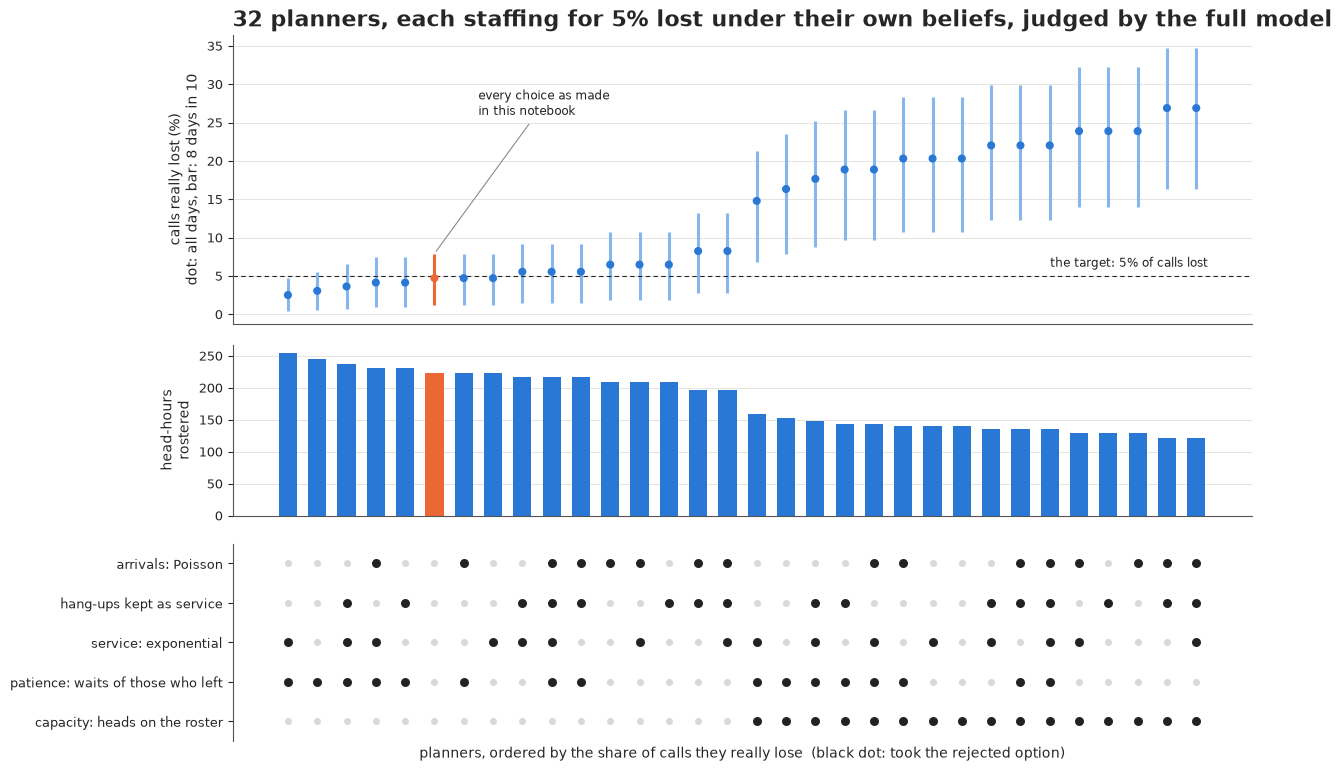

In [27]:
ws = worlds.sort_values("lost").reset_index(drop=True)
fig, axes = plt.subplots(3, 1, figsize=(12.5, 7.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.3, 1.5], "hspace": 0.08})
xw = np.arange(len(ws))
is_ours = (ws["rejected"] == 0).to_numpy()
ax = axes[0]
ax.vlines(xw, ws["lo"] * 100, ws["hi"] * 100, color=np.where(is_ours, ORANGE, "#86b6ef"), lw=2.2)
ax.scatter(xw, ws["lost"] * 100, s=34, color=np.where(is_ours, ORANGE, BLUE), zorder=3, lw=0)
ax.axhline(5, color=INK, lw=0.8, ls=(0, (4, 3)))
ax.text(len(ws) - 0.6, 6.2, "the target: 5% of calls lost", ha="right", fontsize=8.5, color=INK)
ax.annotate("every choice as made\nin this notebook", (xw[is_ours][0], ws["hi"][is_ours].iloc[0] * 100),
            (xw[is_ours][0] + 1.5, 26), fontsize=8.8, color=INK, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_ylabel("calls really lost (%)\ndot: all days, bar: 8 days in 10")
ax.set_title("32 planners, each staffing for 5% lost under their own beliefs, judged by the full model", loc="left")
tidy(ax)
ax = axes[1]
ax.bar(xw, ws["heads-hours"], width=0.62, color=np.where(is_ours, ORANGE, BLUE))
ax.set_ylabel("head-hours\nrostered")
tidy(ax)
ax = axes[2]
labels = {"arrivals": "arrivals: Poisson", "hangups": "hang-ups kept as service", "shape": "service: exponential",
          "patience": "patience: waits of those who left", "capacity": "capacity: heads on the roster"}
for r_, f in enumerate(FORKS):
    on = ws[f].to_numpy() == 1
    ax.scatter(xw[~on], np.full((~on).sum(), r_), s=26, color=LIGHT, lw=0)
    ax.scatter(xw[on], np.full(on.sum(), r_), s=42, color=INK, lw=0)
ax.set_yticks(range(len(FORKS)), [labels[f] for f in FORKS])
ax.set_ylim(len(FORKS) - 0.5, -0.5)
ax.set_xticks([])
ax.set_xlabel("planners, ordered by the share of calls they really lose  (black dot: took the rejected option)")
ax.grid(False)
ax.spines[["top", "right", "bottom"]].set_visible(False);

Read the figure from the bottom. Each column is a planner. The black dots say which rejected options
that planner took, the bars are the head-hours posted, and the top panel is what the full model says
happens. The orange column is this notebook: 223 head-hours and 4.7% of calls lost (the search here
turns the dial in finer steps than part 6 and stops one notch earlier). Rosters come in whole agents,
so planners with slightly different beliefs often post nearly the same one, and the curve moves in
steps.

**One choice dominates.** The sixteen planners on the right all counted heads as agents. They post
about 120 to 160 head-hours where the others post 200 to 255, and they lose between 15% and 27% of
calls while believing they lose 5. This was the choice we did not know we were making until the
simulator failed its first test. It outweighs the other four together.

**Three choices are of similar size, and one of them points the other way.** Poisson arrivals alone
save 14 head-hours and take the loss from 4.7% to 6.5%. Keeping the agents' hang-ups as service, which
makes the agents look about 5% faster, does the same. Naive patience alone adds 22 head-hours and
brings the loss down to 3.1%: a planner who thinks callers leave after 79 seconds staffs for a
stampede that does not come. Planners who combine an error of each sign land near the target, as
Erlang's formulas did in part 6. Errors that cancel are not a method. They do explain why crude
staffing rules survive in practice.

**One choice does not matter.** The shape of the service time is the assumption that queueing texts
discuss most. With the mean held fixed, the planner who believes in exponential calls posts the same
roster as we do, to the last agent. In a queue where callers can leave, the mean call length does the
work.

The lesson for the next analysis is about where to spend effort. We spent most of ours, in pages, on
distributions. The number that moved the answer most was a definition: what counts as an agent.

## Summary

- **A staffing answer is a chain of models, and its weakest link was not on the list.** Arrivals,
  service and patience were planned from the start. The link that moved the roster most, how many
  agents are really answering, appeared only when the assembled simulator predicted 4% of calls lost
  on days that lost 14%. *Limit:* capacity is inferred from calls in progress, not observed, and the
  conversion to heads (about 0.64) is the least certain number here.
- **Arrivals: the uncertainty that matters is the day, not the parameters.** Poisson fails every
  check. Negative binomial noise passes the usual one and still fails, because real surprises last all
  day: the day effect has a standard deviation of 0.15 on the log scale, with a tilt between morning
  and evening on top. *Limit:* one year of data; December's level is treated as known.
- **Service: what counts as a call, and when it was made, mattered more than the shape.** About 5.5%
  of served calls before November were agents hanging up; a mixture sets them aside. Call lengths
  drift by up to 14% with the month and 16% with the hour, which we learned from a failed test, not
  from the service data. Exponential against lognormal changed nothing in the roster.
- **Patience: censoring is most of the story.** Callers who hung up had waited 79 seconds on average;
  the patience of all callers is seven to eleven minutes, with a hazard that peaks on joining the
  queue and again at one minute. *Limit:* patience may itself depend on how well the centre is
  staffed, and we carry 1999's patience over to better rosters.
- **The simulator failed twice, usefully.** With measured capacity and drifting call lengths, tuned
  on January to June, it gives 15.5% lost against 13.8% on July to December and a mean wait of 63
  seconds against 60. *Limit:* it stays too gloomy in quiet hours.
- **The decision is a frontier.** 144 agent-hours answering (13 at the peak) lose 4% of calls on a
  December Sunday; the bank's roughly 99 lose one in six in the model (the four real Sundays lost 7%
  to 29%). Planning for the average day understates the
  loss by half; holding 5% on nine days in ten takes 166 agent-hours.
- **Erlang's formula landed on the right roster by cancellation.** Ignoring busy days and ignoring
  hang-ups push in opposite directions; fixing only one of them (Erlang A) did worse than fixing
  neither.

## Try it yourself

1. **Replan at 10:00.** By mid-morning the day has shown its hand. Weight the 2,000 simulated days of
   part 2 by the negative binomial likelihood of a real morning's first three hourly counts, and you
   have a posterior for the rest of that day. How much of the gap between the average roster (144
   agent-hours) and the cautious one (166) could a manager with on-call agents save?
2. **Two kinds of caller.** Fit the piecewise hazard separately for priority customers
   (`priority == 2`) and the rest, and give priority callers their 90-second head start in
   `simulate_day` by ordering the queue on arrival time minus 90. Does the pooled hazard misstate the
   loss, and who bears it?
3. **Another month, and the days we set aside.** Plan a Sunday in April (`month=4` in `new_day_rates`
   and `mean_service`), when calls ran 14% longer: how many more agent-hours does 5% take? Then put
   the 14 quiet days back into part 2 and see what the day effect, and the roster, make of them.

In [28]:
print(f"total run time: {time.time() - T_START:.0f} s")

total run time: 135 s
